In [1]:
import pandas as pd

In [2]:
obs_raw = pd.read_parquet("../../data/output/observations.parquet")
photo_raw = pd.read_parquet("../../data/output/photos.parquet")
print(f"Observation shape: {obs_raw.shape}")
print(f"Photos shape: {photo_raw.shape}")

Observation shape: (11463, 33)
Photos shape: (30912, 9)


In [3]:
obs_raw.columns

Index(['observation_id', 'observation_uri', 'partner_observation_id',
       'partner_observation_url', 'taxon_id', 'taxon_name', 'taxon_rank',
       'quality_grade', 'observation_license_code', 'predator_prey_role',
       'preferred_common_name', 'latitude', 'longitude', 'positional_accuracy',
       'country', 'state', 'county', 'town', 'photo_count', 'kingdom_id',
       'kingdom_name', 'phylum_id', 'phylum_name', 'class_id', 'class_name',
       'order_id', 'order_name', 'family_id', 'family_name', 'genus_id',
       'genus_name', 'species_id', 'species_name'],
      dtype='str')

In [4]:
photo_raw.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'url', 'square_url',
       'small_url', 'medium_url', 'large_url', 'original_url'],
      dtype='str')

In [5]:
# Since we are just testing, i am only focusing on the columns that are needed for the biocap
# Will include other columns like country, state, etc later for analysis


In [6]:
obs_raw.isna().sum()

observation_id                  0
observation_uri                 0
partner_observation_id       2665
partner_observation_url      1999
taxon_id                        0
taxon_name                      0
taxon_rank                      0
quality_grade                   0
observation_license_code        0
predator_prey_role            153
preferred_common_name         999
latitude                       16
longitude                      16
positional_accuracy          2467
country                     11463
state                       11463
county                      11463
town                        11463
photo_count                     0
kingdom_id                      0
kingdom_name                    0
phylum_id                       0
phylum_name                     0
class_id                       19
class_name                     19
order_id                       14
order_name                     14
family_id                       7
family_name                     7
genus_id      

In [7]:
obs_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 11463 entries, 0 to 11462
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   observation_id            11463 non-null  int64  
 1   observation_uri           11463 non-null  str    
 2   partner_observation_id    8798 non-null   Int64  
 3   partner_observation_url   9464 non-null   str    
 4   taxon_id                  11463 non-null  int64  
 5   taxon_name                11463 non-null  str    
 6   taxon_rank                11463 non-null  str    
 7   quality_grade             11463 non-null  str    
 8   observation_license_code  11463 non-null  str    
 9   predator_prey_role        11310 non-null  str    
 10  preferred_common_name     10464 non-null  str    
 11  latitude                  11447 non-null  float64
 12  longitude                 11447 non-null  float64
 13  positional_accuracy       8996 non-null   float64
 14  country          

In [8]:
# For now, skip the rows where partner id is blank
obs_w_partners = obs_raw.dropna(subset=['partner_observation_id'])
obs_w_partners.info()

<class 'pandas.DataFrame'>
Index: 8798 entries, 0 to 11462
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   observation_id            8798 non-null   int64  
 1   observation_uri           8798 non-null   str    
 2   partner_observation_id    8798 non-null   Int64  
 3   partner_observation_url   8798 non-null   str    
 4   taxon_id                  8798 non-null   int64  
 5   taxon_name                8798 non-null   str    
 6   taxon_rank                8798 non-null   str    
 7   quality_grade             8798 non-null   str    
 8   observation_license_code  8798 non-null   str    
 9   predator_prey_role        8795 non-null   str    
 10  preferred_common_name     7994 non-null   str    
 11  latitude                  8784 non-null   float64
 12  longitude                 8784 non-null   float64
 13  positional_accuracy       6832 non-null   float64
 14  country                

In [9]:
obs_w_partners["partner_observation_id"] = (
    obs_w_partners["partner_observation_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
)

obs_w_partners["observation_id"] = (
    obs_w_partners["observation_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
)

obs_w_partners["valid_partner"] = (
    obs_w_partners["partner_observation_id"]
    .isin(obs_w_partners["observation_id"])
)

In [10]:
obs_valid_partners = obs_w_partners[obs_w_partners["valid_partner"]==True]
obs_valid_partners[["observation_id","partner_observation_id","valid_partner"]].head()

,observation_id,partner_observation_id,valid_partner
0,55574,55575,True
1,55575,55574,True
3,414645,414707,True
4,414707,414645,True
9,509046,66466454,True


In [11]:
# create interaction df

In [12]:
# Join the obs and photos
obs_valid_partners["observation_id"] = obs_valid_partners["observation_id"].astype(str)
photo_raw["observation_id"] = photo_raw["observation_id"].astype(str)
whole_raw = pd.merge(photo_raw, obs_valid_partners, on='observation_id', how='outer')
whole_raw

,observation_id,photo_id,photo_license_code,url,square_url,small_url,medium_url,large_url,original_url,observation_uri,...,class_name,order_id,order_name,family_id,family_name,genus_id,genus_name,species_id,species_name,valid_partner
0,100010656,166854248.0,cc-by-nc-nd,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10003229,114145431.0,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100052837,166933111.0,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100052837,166933119.0,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100052837,166933123.0,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31544,99990955,166796310.0,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/99990955,...,Magnoliopsida,47132.0,Rosales,50998.0,Moraceae,50999.0,Ficus,585956.0,Ficus burkei,True
31545,99990955,166796399.0,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/99990955,...,Magnoliopsida,47132.0,Rosales,50998.0,Moraceae,50999.0,Ficus,585956.0,Ficus burkei,True
31546,99990955,166796459.0,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/99990955,...,Magnoliopsida,47132.0,Rosales,50998.0,Moraceae,50999.0,Ficus,585956.0,Ficus burkei,True
31547,99990956,166796339.0,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/99990956,...,Aves,793433.0,Musophagiformes,7194.0,Musophagidae,1505973.0,Gallirex,1505988.0,Gallirex porphyreolophus,True


In [13]:
whole_valid =  whole_raw[whole_raw["valid_partner"]==True]
whole_valid[["observation_id", "photo_id", "partner_observation_id", "valid_partner"]]

,observation_id,photo_id,partner_observation_id,valid_partner
5,100053359,166934121.0,100053594,True
6,100053359,166934128.0,100053594,True
7,100053594,NaN,100053359,True
19,100191270,167181731.0,100191271,True
20,100191271,NaN,100191270,True
...,...,...,...,...
31544,99990955,166796310.0,99990956,True
31545,99990955,166796399.0,99990956,True
31546,99990955,166796459.0,99990956,True
31547,99990956,166796339.0,99990955,True


In [14]:
whole_valid.dropna(subset=["photo_id"],inplace=True)

In [15]:
whole_valid[["observation_id", "photo_id", "partner_observation_id", "valid_partner"]]

,observation_id,photo_id,partner_observation_id,valid_partner
5,100053359,166934121.0,100053594,True
6,100053359,166934128.0,100053594,True
19,100191270,167181731.0,100191271,True
21,100213596,167226150.0,100213691,True
22,100213596,167226155.0,100213691,True
...,...,...,...,...
31544,99990955,166796310.0,99990956,True
31545,99990955,166796399.0,99990956,True
31546,99990955,166796459.0,99990956,True
31547,99990956,166796339.0,99990955,True


In [16]:
whole_valid["photo_id"] = whole_valid["photo_id"].astype("Int64").astype(str)
whole_valid["file_name"] = (
    "obs_"
    + whole_valid["observation_id"].astype(str)
    + "_photo_"
    + whole_valid["photo_id"].astype(str)
)

In [17]:
from pathlib import Path

folder_path = "../../image_dataset_raw/"

# Get all filenames without extensions
existing_files = {f.stem for f in Path(folder_path).iterdir() if f.is_file()}

whole_valid["file_exists"] = whole_valid["file_name"].isin(existing_files)

In [18]:
file_existing = whole_valid[whole_valid["file_exists"]==True]

In [19]:
from pathlib import Path

ROOT = Path("/rs1/researchers/a/amallav/species_classification/ecological_informatics").resolve()

IMAGE_DIR = ROOT / "image_dataset_raw"

# Index existing images once for efficient matching
image_lookup = {
    path.stem: str(path.resolve())
    for path in IMAGE_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
}

# Match using the file_name column
file_existing["local_file_path"] = (
    file_existing["file_name"]
    .astype(str)
    .map(image_lookup)
)

In [20]:
total = len(file_existing)
matched = file_existing["local_file_path"].notna().sum()

print(f"Total records: {total}")
print(f"Matched images: {matched}")
print(f"Missing images: {total - matched}")

display(
    file_existing[
        ["file_name", "local_file_path"]
    ].head(20)
)

Total records: 8623
Matched images: 8623
Missing images: 0


,file_name,local_file_path
5,obs_100053359_photo_166934121,/rs1/researchers/a/amallav/species_classificat...
6,obs_100053359_photo_166934128,/rs1/researchers/a/amallav/species_classificat...
19,obs_100191270_photo_167181731,/rs1/researchers/a/amallav/species_classificat...
39,obs_100598485_photo_167922022,/rs1/researchers/a/amallav/species_classificat...
40,obs_100598485_photo_167922046,/rs1/researchers/a/amallav/species_classificat...
41,obs_100598485_photo_167922061,/rs1/researchers/a/amallav/species_classificat...
42,obs_100598485_photo_167922069,/rs1/researchers/a/amallav/species_classificat...
43,obs_100598485_photo_167922076,/rs1/researchers/a/amallav/species_classificat...
44,obs_100598485_photo_167922081,/rs1/researchers/a/amallav/species_classificat...
45,obs_100598485_photo_167922088,/rs1/researchers/a/amallav/species_classificat...


In [21]:
file_existing.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'url', 'square_url',
       'small_url', 'medium_url', 'large_url', 'original_url',
       'observation_uri', 'partner_observation_id', 'partner_observation_url',
       'taxon_id', 'taxon_name', 'taxon_rank', 'quality_grade',
       'observation_license_code', 'predator_prey_role',
       'preferred_common_name', 'latitude', 'longitude', 'positional_accuracy',
       'country', 'state', 'county', 'town', 'photo_count', 'kingdom_id',
       'kingdom_name', 'phylum_id', 'phylum_name', 'class_id', 'class_name',
       'order_id', 'order_name', 'family_id', 'family_name', 'genus_id',
       'genus_name', 'species_id', 'species_name', 'valid_partner',
       'file_name', 'file_exists', 'local_file_path'],
      dtype='str')

In [22]:
file_existing.info()

<class 'pandas.DataFrame'>
Index: 8623 entries, 5 to 31548
Data columns (total 45 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   observation_id            8623 non-null   str    
 1   photo_id                  8623 non-null   str    
 2   photo_license_code        8623 non-null   str    
 3   url                       8623 non-null   str    
 4   square_url                0 non-null      object 
 5   small_url                 0 non-null      object 
 6   medium_url                0 non-null      object 
 7   large_url                 0 non-null      object 
 8   original_url              0 non-null      object 
 9   observation_uri           8623 non-null   str    
 10  partner_observation_id    8623 non-null   str    
 11  partner_observation_url   8623 non-null   str    
 12  taxon_id                  8623 non-null   float64
 13  taxon_name                8623 non-null   str    
 14  taxon_rank             

In [23]:
df_clean = file_existing.drop(
    columns=[
        "square_url", "small_url", "medium_url", "large_url", "original_url",
        "country", "county", "state", "town",
        "kingdom_id", "phylum_id", "class_id", "order_id",
        "family_id", "genus_id", "species_id", "photo_count", "taxon_id", "quality_grade",
    ]
)

In [24]:
df_clean.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'url',
       'observation_uri', 'partner_observation_id', 'partner_observation_url',
       'taxon_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'preferred_common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path'],
      dtype='str')

In [25]:
df_clean.rename(
    columns={
        "observation_uri": "obs_url",
        "url": "photo_url",
        "taxon_name": "scientific_name",
        "preferred_common_name":"common_name"
    },
    inplace=True
)

In [26]:
df_clean.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path'],
      dtype='str')

# Add the prompts to this dataset

In [27]:
file_existing.head()

,observation_id,photo_id,photo_license_code,url,square_url,small_url,medium_url,large_url,original_url,observation_uri,...,family_id,family_name,genus_id,genus_name,species_id,species_name,valid_partner,file_name,file_exists,local_file_path
5,100053359,166934121,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/10005...,...,7194.0,Musophagidae,7246.0,Crinifer,1506034.0,Crinifer concolor,True,obs_100053359_photo_166934121,True,/rs1/researchers/a/amallav/species_classificat...
6,100053359,166934128,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/10005...,...,7194.0,Musophagidae,7246.0,Crinifer,1506034.0,Crinifer concolor,True,obs_100053359_photo_166934128,True,/rs1/researchers/a/amallav/species_classificat...
19,100191270,167181731,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/10019...,...,11853.0,Hirundinidae,11863.0,Progne,11867.0,Progne subis,True,obs_100191270_photo_167181731,True,/rs1/researchers/a/amallav/species_classificat...
39,100598485,167922022,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/10059...,...,47918.0,Saturniidae,372597.0,Cirina,372596.0,Cirina forda,True,obs_100598485_photo_167922022,True,/rs1/researchers/a/amallav/species_classificat...
40,100598485,167922046,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,None,None,None,None,None,https://www.inaturalist.org/observations/10059...,...,47918.0,Saturniidae,372597.0,Cirina,372596.0,Cirina forda,True,obs_100598485_photo_167922046,True,/rs1/researchers/a/amallav/species_classificat...


In [28]:


prompt1 = pd.read_parquet("../prompt_engineering/output/dataset_animalia_with_prompts_1.parquet")
prompt2 = pd.read_parquet("../prompt_engineering/output/dataset_animalia_with_prompts_2.parquet")
prompt3 = pd.read_parquet("../prompt_engineering/output/dataset_animalia_with_prompts_3.parquet")

prompt_whole = pd.concat([prompt1, prompt2, prompt3], axis=0, ignore_index=True)

In [29]:
prompt_whole.head()

,obs_id,photo_id,photo_license_code,photo_url,obs_url,quality_grade,obs_license_code,predator_prey_role,scientific_name,taxon_rank,...,variety_name,tribe_name,country,state,city,file_name,image_byte_size,image_local_path,image_download_url,grounding_dino_prompt
0,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,NaN,NaN,Mexico,Coahuila,Torreón,obs_338604_photo_421440,115373,/rs1/researchers/a/amallav/species_classificat...,https://inaturalist-open-data.s3.amazonaws.com...,"brown bird with long black tail, black back, a..."
1,338604,421441,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,NaN,NaN,Mexico,Coahuila,Torreón,obs_338604_photo_421441,108859,/rs1/researchers/a/amallav/species_classificat...,https://inaturalist-open-data.s3.amazonaws.com...,"brown bird with long black tail, black back, a..."
2,338604,421442,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,NaN,NaN,Mexico,Coahuila,Torreón,obs_338604_photo_421442,88132,/rs1/researchers/a/amallav/species_classificat...,https://inaturalist-open-data.s3.amazonaws.com...,"brown bird with long black tail, black back, a..."
3,338604,421443,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,NaN,NaN,Mexico,Coahuila,Torreón,obs_338604_photo_421443,88391,/rs1/researchers/a/amallav/species_classificat...,https://inaturalist-open-data.s3.amazonaws.com...,"brown bird with long black tail, black back, a..."
4,414645,521779,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/414645,research,cc-by,predator,Lycophidion capense,species,...,NaN,NaN,Zimbabwe,Mashonaland West Province,Hurungwe 7,obs_414645_photo_521779,656481,/rs1/researchers/a/amallav/species_classificat...,https://inaturalist-open-data.s3.amazonaws.com...,"brown snake with dark blotches, narrow head, a..."


In [30]:
df_clean["photo_id"] = df_clean["photo_id"].astype(str)
prompt_whole["photo_id"] = prompt_whole["photo_id"].astype(str)

df_clean = df_clean.merge(
    prompt_whole[["photo_id", "grounding_dino_prompt"]],
    on="photo_id",
    how="left"
)

df_clean.info()


<class 'pandas.DataFrame'>
RangeIndex: 8623 entries, 0 to 8622
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   observation_id            8623 non-null   str    
 1   photo_id                  8623 non-null   str    
 2   photo_license_code        8623 non-null   str    
 3   photo_url                 8623 non-null   str    
 4   obs_url                   8623 non-null   str    
 5   partner_observation_id    8623 non-null   str    
 6   partner_observation_url   8623 non-null   str    
 7   scientific_name           8623 non-null   str    
 8   taxon_rank                8623 non-null   str    
 9   observation_license_code  8623 non-null   str    
 10  predator_prey_role        8608 non-null   str    
 11  common_name               8063 non-null   str    
 12  latitude                  8623 non-null   float64
 13  longitude                 8623 non-null   float64
 14  positional_accuracy

In [31]:
df_clean.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt'],
      dtype='str')

# Object Detection

In [32]:
from pathlib import Path
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import os
import gc
import inspect
import torch
import pandas as pd


/usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [33]:

from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection



In [34]:
# Directories
OUTPUT_DIR = Path(
    "/rs1/researchers/a/amallav/species_classification/"
    "ecological_informatics/notebooks/interaction/groundingdino/outputs/"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



In [35]:

# Model
MODEL_ID = "IDEA-Research/grounding-dino-base"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Detection thresholds
BOX_THRESHOLD = 0.25
TEXT_THRESHOLD = 0.25

# Number of rows per checkpoint
CHUNK_SIZE = 100

print("Device:", DEVICE)
print("Total rows:", len(df_clean))
print("Output directory:", OUTPUT_DIR)
print(f"GPU device name: {torch.cuda.get_device_name(0)}")

Device: cuda
Total rows: 8623
Output directory: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/interaction/groundingdino/outputs
GPU device name: NVIDIA L40S


## Load GroundingDINO

In [36]:
from pathlib import Path
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

# Project directory
project = Path(
    "/rs1/researchers/a/amallav/species_classification/ecological_informatics"
)

# Existing downloaded GroundingDINO model
MODEL_DIR = (project / "models" / "grounding-dino-base").resolve()

# Verify model configuration exists
if not (MODEL_DIR / "config.json").is_file():
    raise FileNotFoundError(f"GroundingDINO config missing: {MODEL_DIR}")

# Select GPU if available
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


In [37]:

# Load processor directly from local directory
processor = AutoProcessor.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True
)

# Load model weights directly from local directory
model = AutoModelForZeroShotObjectDetection.from_pretrained(
    str(MODEL_DIR),
    local_files_only=True
)

# Move model to GPU and switch to inference mode
model = model.to(DEVICE).eval()

print("GroundingDINO loaded successfully")
print("Model directory:", MODEL_DIR)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

The image processor of type `GroundingDinoImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 1206/1206 [00:00<00:00, 19077.67it/s]


GroundingDINO loaded successfully
Model directory: /rs1/researchers/a/amallav/species_classification/ecological_informatics/models/grounding-dino-base
Device: cuda
GPU: NVIDIA L40S


## detection function

In [57]:


def run_grounding_dino(image_path, prompt):
    TOP_N = 5
    # 1. Load image
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    width, height = image.size

    # 2. Prepare LLaMA-generated prompt
    text = str(prompt).strip()

    # 3. Prepare image and text inputs
    inputs = processor(
        images=image,
        text=text,
        return_tensors="pt"
    ).to(DEVICE)

    # 4. Run GroundingDINO
    with torch.inference_mode():
        outputs = model(**inputs)

    # 5. Prepare postprocessing arguments
    post_params = inspect.signature(
        processor.post_process_grounded_object_detection
    ).parameters

    kwargs = {
        "text_threshold": TEXT_THRESHOLD,
        "target_sizes": [(height, width)]
    }

    # Handle different Transformers versions
    if "box_threshold" in post_params:
        kwargs["box_threshold"] = BOX_THRESHOLD
    else:
        kwargs["threshold"] = BOX_THRESHOLD

    # Some Transformers versions require input_ids
    if "input_ids" in post_params:
        kwargs["input_ids"] = inputs["input_ids"]

    # 6. Convert predictions to pixel coordinates
    result = processor.post_process_grounded_object_detection(
        outputs,
        **kwargs
    )[0]

    boxes = result["boxes"].detach().cpu().tolist()
    scores = result["scores"].detach().cpu().tolist()

    labels = result.get(
        "text_labels",
        result.get("labels", [])
    )

    # 7. Sort detections by confidence score
    order = sorted(
        range(len(scores)),
        key=lambda i: scores[i],
        reverse=True
    )

    # 8. Keep top 5 detections and assign ranks
    detections = []

    for rank, idx in enumerate(order[:TOP_N], start=1):

        box = [float(x) for x in boxes[idx]]

        detections.append({
            "rank": rank,
            "box": box,
            "score": float(scores[idx]),
            "phrase": str(labels[idx])
        })

    # 9. Return detection results
    return {
        "gd_num_boxes": len(detections),
        "gd_all_detections": detections,
        "gd_best_box": detections[0]["box"] if detections else None,
        "gd_best_score": detections[0]["score"] if detections else None,
        "gd_image_width": width,
        "gd_image_height": height,
        "gd_status": "success" if detections else "no_detection",
        "gd_error": None
    }

## Run GroundingDINO on the entire dataset

In [58]:
import torch

print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))
    print("Supported architectures:", torch.cuda.get_arch_list())

    # Test whether a basic CUDA operation actually works
    try:
        x = torch.randn(100, 100, device="cuda")
        y = x @ x
        torch.cuda.synchronize()
        print("Basic CUDA test: PASSED")
    except Exception as e:
        print("Basic CUDA test: FAILED")
        print(repr(e))

PyTorch: 2.5.1
PyTorch CUDA: 12.1
CUDA available: True
GPU: NVIDIA L40S
Compute capability: (8, 9)
Supported architectures: ['sm_50', 'sm_60', 'sm_61', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']
Basic CUDA test: PASSED


In [71]:
from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import torch

# 1. Copy original dataframe
df_gd = df_clean.copy().reset_index(drop=True)

# 2. Initialize image-level detection columns
result_cols = [
    "gd_num_boxes",
    "gd_all_detections",
    "gd_best_box",
    "gd_best_score",
    "gd_image_width",
    "gd_image_height",
    "gd_status",
    "gd_error"
]

for col in result_cols:
    df_gd[col] = None

# 3. Define output paths
output_dir = Path("groundingdino/full_run")
output_dir.mkdir(parents=True, exist_ok=True)

image_output_path = output_dir / "grounding_dino_results.parquet"
box_output_path = output_dir / "grounding_dino_boxes.parquet"

# 4. Number of images to process
# n = 10
n = len(df_gd)  # Uncomment to process entire dataset

In [72]:
# Store individual bounding-box records
box_records = []

# 5. Process images
for i in tqdm(range(n), desc="GroundingDINO"):

    try:
        image_path = df_gd.at[i, "local_file_path"]
        prompt = df_gd.at[i, "grounding_dino_prompt"]

        # Validate image path
        if pd.isna(image_path) or not Path(str(image_path)).is_file():
            raise FileNotFoundError(f"Image missing: {image_path}")

        # Validate LLaMA-generated prompt
        if pd.isna(prompt) or not str(prompt).strip():
            raise ValueError("Missing GroundingDINO prompt")

        # Run GroundingDINO inference
        result = run_grounding_dino(
            image_path=str(image_path),
            prompt=str(prompt)
        )

        # 6. Store image-level detection results
        for col, value in result.items():
            df_gd.at[i, col] = value

        # 7. Store each detected box as a separate row
        for detection in result["gd_all_detections"]:

            x0, y0, x1, y1 = detection["box"]

            # Copy ALL original source columns
            box_row = df_clean.iloc[i].to_dict()

            # Add detection-specific columns
            box_row.update({
                "source_row": i,
                "rank": detection["rank"],
                "score": detection["score"],
                "text_label": detection["phrase"],
                "x0": x0,
                "y0": y0,
                "x1": x1,
                "y1": y1,
                "img_width": result["gd_image_width"],
                "img_height": result["gd_image_height"],
                "gd_num_boxes": result["gd_num_boxes"],
                "gd_status": result["gd_status"]
            })

            box_records.append(box_row)

    except Exception as e:

        # Record the error without losing other results
        df_gd.at[i, "gd_num_boxes"] = 0
        df_gd.at[i, "gd_all_detections"] = []
        df_gd.at[i, "gd_status"] = "error"
        df_gd.at[i, "gd_error"] = repr(e)

        print(f"\nError at row {i}: {repr(e)}")

        # Stop on CUDA errors because the GPU context may be invalid
        if isinstance(e, RuntimeError) and "CUDA" in str(e).upper():

            df_gd.to_parquet(
                image_output_path,
                index=False
            )

            pd.DataFrame(box_records).to_parquet(
                box_output_path,
                index=False
            )

            raise

    # 8. Save checkpoints every 100 images
    if (i + 1) % 100 == 0:

        df_gd.to_parquet(
            image_output_path,
            index=False
        )

        pd.DataFrame(box_records).to_parquet(
            box_output_path,
            index=False
        )

# 9. Save final image-level results
df_gd.to_parquet(
    image_output_path,
    index=False
)

# 10. Create and save final box-level dataframe
box_columns = list(df_clean.columns) + [
    "source_row",
    "rank",
    "score",
    "text_label",
    "x0", "y0", "x1", "y1",
    "img_width",
    "img_height",
    "gd_num_boxes",
    "gd_status"
]

df_boxes = pd.DataFrame(
    box_records,
    columns=box_columns
)

df_boxes.to_parquet(
    box_output_path,
    index=False
)

# 11. Print summary
print("\nImage results:", image_output_path.resolve())
print("Box results:", box_output_path.resolve())

print("\nDetection status:")
print(df_gd["gd_status"].value_counts(dropna=False))

print("\nTotal images attempted:", n)
print("Total bounding boxes:", len(df_boxes))
print("Images with detections:", df_boxes["source_row"].nunique())

GroundingDINO:   0%|                                                                                                    | 0/10 [00:00<?, ?it/s]/usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/transformers/models/grounding_dino/processing_grounding_dino.py:96: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)
GroundingDINO: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:02<00:00,  4.69it/s]


Image results: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/interaction/groundingdino/test/grounding_dino_results.parquet
Box results: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/interaction/groundingdino/test/grounding_dino_boxes.parquet

Detection status:
gd_status
None       8613
success      10
Name: count, dtype: int64

Total images attempted: 10
Total bounding boxes: 17
Images with detections: 10


In [73]:
import numpy as np

# Box dimensions
df_boxes["box_width"] = df_boxes["x1"] - df_boxes["x0"]
df_boxes["box_height"] = df_boxes["y1"] - df_boxes["y0"]



In [74]:
# Fraction of image covered by the bounding box
df_boxes["box_area_frac"] = (
    df_boxes["box_width"] * df_boxes["box_height"]
) / (
    df_boxes["img_width"] * df_boxes["img_height"]
)


In [75]:

# Bounding-box aspect ratio
df_boxes["aspect_ratio"] = (
    df_boxes["box_width"] / df_boxes["box_height"].replace(0, np.nan)
)


In [76]:

# Distance between box center and image center
box_cx = (df_boxes["x0"] + df_boxes["x1"]) / 2
box_cy = (df_boxes["y0"] + df_boxes["y1"]) / 2

image_cx = df_boxes["img_width"] / 2
image_cy = df_boxes["img_height"] / 2

image_diagonal = np.hypot(
    df_boxes["img_width"],
    df_boxes["img_height"]
)

df_boxes["center_offset_frac"] = (
    np.hypot(box_cx - image_cx, box_cy - image_cy)
    / image_diagonal
)


In [77]:

# Validate bounding-box coordinates
df_boxes["is_valid_box"] = (
    (df_boxes["x0"] >= 0) &
    (df_boxes["y0"] >= 0) &
    (df_boxes["x1"] > df_boxes["x0"]) &
    (df_boxes["y1"] > df_boxes["y0"]) &
    (df_boxes["x1"] <= df_boxes["img_width"]) &
    (df_boxes["y1"] <= df_boxes["img_height"])
)


In [78]:
df_boxes[df_boxes["is_valid_box"]== False]

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,img_width,img_height,gd_num_boxes,gd_status,box_width,box_height,box_area_frac,aspect_ratio,center_offset_frac,is_valid_box


In [79]:
df_boxes.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'is_valid_box'],
      dtype='str')

In [80]:

# Save enriched per-box results
df_boxes.to_parquet(
    "groundingdino/full_run/grounding_dino_boxes.parquet",
    index=False
)

In [81]:
# Check that all original source columns are preserved
print("Source columns preserved:",
      set(df_clean.columns).issubset(df_boxes.columns))

# Preview box-level detections
display(
    df_boxes[
        [
            "observation_id",
            "photo_id",
            "species_name",
            "rank",
            "score",
            "text_label",
            "x0", "y0", "x1", "y1"
        ]
    ].head(15)
)

Source columns preserved: True


,observation_id,photo_id,species_name,rank,score,text_label,x0,y0,x1,y1
0,100053359,166934121,Crinifer concolor,1,0.910047,grey bird,512.604492,271.364532,768.290649,513.771179
1,100053359,166934128,Crinifer concolor,1,0.865069,grey bird,380.584351,305.904846,723.820190,578.211365
2,100191270,167181731,Progne subis,1,0.602173,dark bird,371.743958,588.063843,546.389221,697.053040
3,100598485,167922022,Cirina forda,1,0.534688,brown butterfly,286.668823,98.381165,765.579346,586.356934
4,100598485,167922022,Cirina forda,2,0.262951,brown butterfly,287.249542,68.755608,833.561279,586.197266
5,100598485,167922046,Cirina forda,1,0.833971,brown butterfly,100.266052,50.058380,724.881165,637.920532
6,100598485,167922061,Cirina forda,1,0.385959,brown butterfly,364.503998,278.293243,813.707153,682.839050
7,100598485,167922061,Cirina forda,2,0.366572,brown butterfly,152.492432,98.475487,821.641052,675.461975
8,100598485,167922061,Cirina forda,3,0.280549,brown butterfly,149.163589,108.050789,569.360901,422.713379
9,100598485,167922069,Cirina forda,1,0.554148,brown butterfly,191.734894,84.032776,498.681824,944.353455


## Evaluate the results

In [1]:
import pandas as pd
gd_results = pd.read_parquet("groundingdino/full_run/grounding_dino_results.parquet")
gd_boxes = pd.read_parquet("groundingdino/full_run/grounding_dino_boxes.parquet")

In [2]:
gd_results.head()

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,local_file_path,grounding_dino_prompt,gd_num_boxes,gd_all_detections,gd_best_box,gd_best_score,gd_image_width,gd_image_height,gd_status,gd_error
0,100053359,166934121,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10005...,100053594,https://www.inaturalist.org/observations/10005...,Crinifer concolor,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"Grey bird with black throat patch, long black ...",1,"[{'rank': 1, 'box': [512.6045532226562, 271.36...","[512.6045532226562, 271.36456298828125, 768.29...",0.910060,1024,651,success,None
1,100053359,166934128,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10005...,100053594,https://www.inaturalist.org/observations/10005...,Crinifer concolor,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"Grey bird with black throat patch, long black ...",1,"[{'rank': 1, 'box': [380.5843200683594, 305.90...","[380.5843200683594, 305.9048767089844, 723.820...",0.865117,1024,726,success,None
2,100191270,167181731,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10019...,100191271,https://www.inaturalist.org/observations/10019...,Progne subis,species,cc-by-nc,...,/rs1/researchers/a/amallav/species_classificat...,"dark bird with iridescent purple back, white u...",1,"[{'rank': 1, 'box': [371.7440185546875, 588.06...","[371.7440185546875, 588.0638427734375, 546.389...",0.602191,1024,768,success,None
3,100598485,167922022,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10059...,100600106,https://www.inaturalist.org/observations/10060...,Cirina forda,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"brown butterfly with pale yellow wings, dark v...",2,"[{'rank': 1, 'box': [286.6688232421875, 98.381...","[286.6688232421875, 98.38133239746094, 765.579...",0.534855,1024,684,success,None
4,100598485,167922046,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10059...,100600106,https://www.inaturalist.org/observations/10060...,Cirina forda,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"brown butterfly with pale yellow wings, dark v...",1,"[{'rank': 1, 'box': [100.26614379882812, 50.05...","[100.26614379882812, 50.0583610534668, 724.881...",0.833905,1024,692,success,None


In [3]:
gd_results.shape

(8623, 35)

In [13]:
gd_results[gd_results["gd_status"]=="no_detection"]
# gd_results["gd_status"].unique()

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,local_file_path,grounding_dino_prompt,gd_num_boxes,gd_all_detections,gd_best_box,gd_best_score,gd_image_width,gd_image_height,gd_status,gd_error
102,103688007,173585165,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10368...,103688009,https://www.inaturalist.org/observations/10368...,Plectropterus gambensis niger,subspecies,cc-by-nc,...,/rs1/researchers/a/amallav/species_classificat...,black and white goose with distinctive white f...,0,[],None,NaN,1024,768,no_detection,None
206,106219266,178400362,cc0,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10621...,106219205,https://www.inaturalist.org/observations/10621...,Sphyrapicus ruber,species,cc0,...,/rs1/researchers/a/amallav/species_classificat...,"Red-breasted woodpecker with red cap, black ba...",0,[],None,NaN,768,1024,no_detection,None
844,138472991,236685464,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/13847...,138481779,https://www.inaturalist.org/observations/13848...,Sceloporus occidentalis,species,cc-by-nc,...,/rs1/researchers/a/amallav/species_classificat...,brown lizard with distinctive light and dark s...,0,[],None,NaN,768,1024,no_detection,None
1167,149034511,256738115,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/14903...,149034514,https://www.inaturalist.org/observations/14903...,Heliosciurus gambianus,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"striped squirrel with reddish-brown back, whit...",0,[],None,NaN,1024,683,no_detection,None
1304,152957191,264111691,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/15295...,152957189,https://www.inaturalist.org/observations/15295...,Nerodia fasciata,species,cc-by-nc,...,/rs1/researchers/a/amallav/species_classificat...,"brown snake with dark brown bands, narrow head...",0,[],None,NaN,1024,683,no_detection,None
4383,287976168,517808367,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/28797...,287976173,https://www.inaturalist.org/observations/28797...,Apis mellifera,species,cc-by-nc,...,/rs1/researchers/a/amallav/species_classificat...,yellow and black striped insect with hairy bod...,0,[],None,NaN,1024,683,no_detection,None
5149,317279483,573303657,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/31727...,317278705,https://www.inaturalist.org/observations/31727...,Sus scrofa,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"bristly pig with curved tusks, dark brown coat...",0,[],None,NaN,1024,768,no_detection,None
7233,414645,28352912,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/414645,414707,https://www.inaturalist.org/observations/414707,Lycophidion capense,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"brown snake with dark blotches, narrow head, a...",0,[],None,NaN,721,1023,no_detection,None
7304,509046,15885882,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/509046,66466454,https://www.inaturalist.org/observations/66466454,Dendroaspis polylepis,species,cc-by,...,/rs1/researchers/a/amallav/species_classificat...,"black snake with black scales, narrow head, an...",0,[],None,NaN,630,1024,no_detection,None


In [4]:
gd_boxes.head()

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,img_width,img_height,gd_num_boxes,gd_status,box_width,box_height,box_area_frac,aspect_ratio,center_offset_frac,is_valid_box
0,100053359,166934121,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10005...,100053594,https://www.inaturalist.org/observations/10005...,Crinifer concolor,species,cc-by,...,1024,651,1,success,255.686890,242.406677,0.092976,1.054785,0.119418,True
1,100053359,166934128,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10005...,100053594,https://www.inaturalist.org/observations/10005...,Crinifer concolor,species,cc-by,...,1024,726,1,success,343.235870,272.306610,0.125723,1.260476,0.070658,True
2,100191270,167181731,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10019...,100191271,https://www.inaturalist.org/observations/10019...,Progne subis,species,cc-by-nc,...,1024,768,1,success,174.645142,108.989319,0.024204,1.602406,0.206189,True
3,100598485,167922022,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10059...,100600106,https://www.inaturalist.org/observations/10060...,Cirina forda,species,cc-by,...,1024,684,2,success,478.910645,487.975540,0.333654,0.981423,0.011474,True
4,100598485,167922022,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10059...,100600106,https://www.inaturalist.org/observations/10060...,Cirina forda,species,cc-by,...,1024,684,2,success,546.311615,517.441681,0.403595,1.055794,0.041039,True


In [14]:
print("Total images:", len(gd_results))
print("Total boxes:", len(gd_boxes))
print("Images with boxes:", gd_boxes["source_row"].nunique())

Total images: 8623
Total boxes: 18145
Images with boxes: 8614


In [16]:
print("\nDetection status:")
print(gd_results["gd_status"].value_counts(dropna=False))

print("\nBoxes per image:")
print(gd_boxes.groupby("source_row").size().value_counts().sort_index())



Detection status:
gd_status
success         8614
no_detection       9
Name: count, dtype: int64

Boxes per image:
1    4137
2    1940
3     996
4     565
5     976
Name: count, dtype: int64


## Validate bounding boxes

In [17]:
# Keep original GroundingDINO coordinates unchanged
coords = ["x0", "y0", "x1", "y1"]



In [19]:
# Convert columns to numeric
for col in coords + ["img_width", "img_height"]:
    gd_boxes[col] = pd.to_numeric(gd_boxes[col], errors="coerce")


In [21]:
import numpy as np
# Check geometry
gd_boxes["invalid_missing"] = (
    ~np.isfinite(gd_boxes[coords + ["img_width", "img_height"]])
    .all(axis=1)
)
gd_boxes["invalid_dimensions"] = (
    (gd_boxes["img_width"] <= 0) |
    (gd_boxes["img_height"] <= 0)
)
gd_boxes["invalid_order"] = (
    (gd_boxes["x0"] >= gd_boxes["x1"]) |
    (gd_boxes["y0"] >= gd_boxes["y1"])
)
gd_boxes["invalid_bounds"] = (
    (gd_boxes["x0"] < 0) |
    (gd_boxes["y0"] < 0) |
    (gd_boxes["x1"] > gd_boxes["img_width"]) |
    (gd_boxes["y1"] > gd_boxes["img_height"])
)
gd_boxes["invalid_box"] = gd_boxes[
    [
        "invalid_missing",
        "invalid_dimensions",
        "invalid_order",
        "invalid_bounds"
    ]
].any(axis=1)

In [22]:
# Detect exact duplicate coordinates within each image

gd_boxes["duplicate_box"] = gd_boxes.duplicated(
    subset=["source_row", "x0", "y0", "x1", "y1"],
    keep="first"
)



Before dropping duplicates: (18145, 50)
After dropping duplicates: (18145, 51)


In [23]:
# Summary
checks = [
    "invalid_missing",
    "invalid_dimensions",
    "invalid_order",
    "invalid_bounds",
    "invalid_box",
    "duplicate_box"
]

print("Total boxes:", len(gd_boxes))
print("\nValidation summary:")
print(gd_boxes[checks].sum())

display(
    gd_boxes.loc[gd_boxes["invalid_box"], [
        "photo_id", "rank", "score",
        "x0", "y0", "x1", "y1",
        "img_width", "img_height"
    ]].head(20)
)

Total boxes: 18145

Validation summary:
invalid_missing         0
invalid_dimensions      0
invalid_order           0
invalid_bounds        704
invalid_box           704
duplicate_box           0
dtype: int64


,photo_id,rank,score,x0,y0,x1,y1,img_width,img_height
45,167964347,1,0.428106,168.392761,-2.002913,353.471161,186.144394,440,300
49,167965404,2,0.272154,-1.542115,-0.088088,197.549088,310.389526,390,311
69,168246131,3,0.335528,-1.166458,600.759949,424.858337,738.190552,1024,740
185,172476773,1,0.846223,34.699707,76.299721,1031.842041,744.322998,1024,831
200,14298043,2,0.306683,384.632935,198.220840,576.419128,531.051758,576,1024
207,172986700,2,0.337093,441.950958,171.008942,960.000671,720.790649,960,1024
215,173293748,2,0.310509,-0.503601,56.722038,997.251648,643.242493,1024,683
228,173549873,1,0.632918,-2.147977,0.660534,468.027832,484.723938,802,602
284,175102959,1,0.699040,-4.133433,100.652611,529.928894,662.061646,1000,667
285,175102963,1,0.762394,-1.120433,104.061394,483.424133,660.915039,1000,667


In [25]:
# Create corrected coordinate columns
gd_boxes["crop_x0"] = gd_boxes["x0"].clip(lower=0)
gd_boxes["crop_y0"] = gd_boxes["y0"].clip(lower=0)

gd_boxes["crop_x1"] = gd_boxes["x1"].clip(lower=0)
gd_boxes["crop_y1"] = gd_boxes["y1"].clip(lower=0)



In [26]:
# Clip to image dimensions
gd_boxes["crop_x0"] = np.minimum(
    gd_boxes["crop_x0"], gd_boxes["img_width"]
)

gd_boxes["crop_x1"] = np.minimum(
    gd_boxes["crop_x1"], gd_boxes["img_width"]
)

gd_boxes["crop_y0"] = np.minimum(
    gd_boxes["crop_y0"], gd_boxes["img_height"]
)

gd_boxes["crop_y1"] = np.minimum(
    gd_boxes["crop_y1"], gd_boxes["img_height"]
)


In [27]:

# Check whether corrected boxes have positive dimensions
gd_boxes["crop_valid"] = (
    ~gd_boxes["invalid_missing"] &
    ~gd_boxes["invalid_dimensions"] &
    ~gd_boxes["invalid_order"] &
    (gd_boxes["crop_x1"] > gd_boxes["crop_x0"]) &
    (gd_boxes["crop_y1"] > gd_boxes["crop_y0"])
)


In [28]:

# Mark boxes changed by clipping
gd_boxes["box_clipped"] = (
    (gd_boxes["crop_x0"] != gd_boxes["x0"]) |
    (gd_boxes["crop_y0"] != gd_boxes["y0"]) |
    (gd_boxes["crop_x1"] != gd_boxes["x1"]) |
    (gd_boxes["crop_y1"] != gd_boxes["y1"])
)



In [30]:
print("Original invalid boxes:", gd_boxes["invalid_box"].sum())
print("Boxes clipped:", gd_boxes["box_clipped"].sum())
print("Usable boxes:", gd_boxes["crop_valid"].sum())
print("Unusable boxes:", (~gd_boxes["crop_valid"]).sum())

Original invalid boxes: 704
Boxes clipped: 704
Usable boxes: 18145
Unusable boxes: 0


In [31]:
gd_boxes.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'is_valid_box', 'invalid_missing',
       'invalid_dimensions', 'invalid_order', 'invalid_bounds', 'invalid_box',
       'duplicate_box', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'crop_valid', 'box_clipped'],
      dtype='str')

In [37]:
df_boxes = gd_boxes.drop(columns=["invalid_missing", "invalid_dimensions", "invalid_order","invalid_bounds","invalid_box","duplicate_box", "crop_valid", "is_valid_box"])
# gd_boxes[gd_boxes["box_clipped"]==True]
# gd_boxes[["box_clipped"]].head()
df_boxes.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'box_clipped'],
      dtype='str')

In [38]:
df_boxes["crop_width"] = (
    df_boxes["crop_x1"] - df_boxes["crop_x0"]
)

df_boxes["crop_height"] = (
    df_boxes["crop_y1"] - df_boxes["crop_y0"]
)

df_boxes["crop_area_fraction"] = (
    df_boxes["crop_width"] * df_boxes["crop_height"]
) / (
    df_boxes["img_width"] * df_boxes["img_height"]
)

display(
    df_boxes[
        ["crop_width", "crop_height", "crop_area_fraction"]
    ].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
)

,crop_width,crop_height,crop_area_fraction
count,18145.000000,18145.000000,18145.000000
mean,378.312282,349.951660,0.235766
std,257.194069,243.532456,0.247266
min,12.110901,11.073990,0.000398
1%,29.327720,28.537799,0.001279
5%,54.545197,52.710364,0.004572
25%,160.962921,153.480408,0.037031
50%,323.698090,295.386627,0.140045
75%,558.779999,495.287216,0.372749
95%,870.229584,856.240646,0.758030


## Visualize the nodetection ones

In [40]:
no_det_df = gd_results[gd_results["gd_status"] == "no_detection"].copy()
print("Number of no-detection images:", len(no_det_df))

Number of no-detection images: 9


In [41]:
display(
    no_det_df[
        [
            "observation_id",
            "photo_id",
            "local_file_path",
            "grounding_dino_prompt",
            "gd_num_boxes",
            "gd_status"
        ]
    ]
)

,observation_id,photo_id,local_file_path,grounding_dino_prompt,gd_num_boxes,gd_status
102,103688007,173585165,/rs1/researchers/a/amallav/species_classificat...,black and white goose with distinctive white f...,0,no_detection
206,106219266,178400362,/rs1/researchers/a/amallav/species_classificat...,"Red-breasted woodpecker with red cap, black ba...",0,no_detection
844,138472991,236685464,/rs1/researchers/a/amallav/species_classificat...,brown lizard with distinctive light and dark s...,0,no_detection
1167,149034511,256738115,/rs1/researchers/a/amallav/species_classificat...,"striped squirrel with reddish-brown back, whit...",0,no_detection
1304,152957191,264111691,/rs1/researchers/a/amallav/species_classificat...,"brown snake with dark brown bands, narrow head...",0,no_detection
4383,287976168,517808367,/rs1/researchers/a/amallav/species_classificat...,yellow and black striped insect with hairy bod...,0,no_detection
5149,317279483,573303657,/rs1/researchers/a/amallav/species_classificat...,"bristly pig with curved tusks, dark brown coat...",0,no_detection
7233,414645,28352912,/rs1/researchers/a/amallav/species_classificat...,"brown snake with dark blotches, narrow head, a...",0,no_detection
7304,509046,15885882,/rs1/researchers/a/amallav/species_classificat...,"black snake with black scales, narrow head, an...",0,no_detection


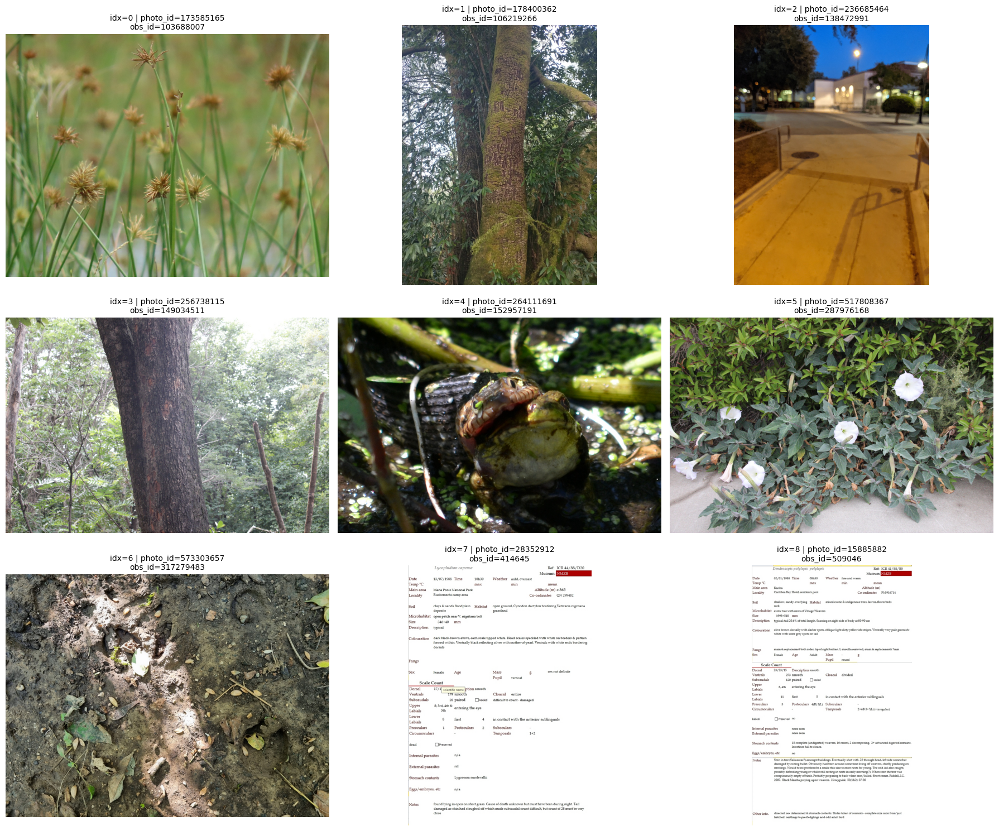

In [42]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
import math

# Reset index for easy plotting
no_det_df = no_det_df.reset_index(drop=True)

n = len(no_det_df)
cols = 3
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten()

for ax in axes[n:]:
    ax.axis("off")

for i, row in no_det_df.iterrows():
    ax = axes[i]
    image_path = row["local_file_path"]

    try:
        img = Image.open(image_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"idx={i} | photo_id={row['photo_id']}\n"
            f"obs_id={row['observation_id']}",
            fontsize=10
        )
    except Exception as e:
        ax.text(
            0.5, 0.5,
            f"Could not open image\n{e}",
            ha="center", va="center", fontsize=10
        )
        ax.set_title(
            f"photo_id={row['photo_id']}",
            fontsize=10
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [44]:
for i, row in no_det_df.iterrows():
    print("=" * 120)
    print(f"Row: {i}")
    print("Observation ID:", row["observation_id"])
    print("Photo ID:", row["photo_id"])
    print("Image path:", row["local_file_path"])
    print("Prompt:", row["grounding_dino_prompt"])
    print("gd_num_boxes:", row["gd_num_boxes"])
    print("gd_status:", row["gd_status"])

Row: 0
Observation ID: 103688007
Photo ID: 173585165
Image path: /rs1/researchers/a/amallav/species_classification/ecological_informatics/image_dataset_raw/obs_103688007_photo_173585165.jpeg
Prompt: black and white goose with distinctive white facial markings and long, pointed wings.
gd_num_boxes: 0
gd_status: no_detection
Row: 1
Observation ID: 106219266
Photo ID: 178400362
Image path: /rs1/researchers/a/amallav/species_classification/ecological_informatics/image_dataset_raw/obs_106219266_photo_178400362.jpeg
Prompt: Red-breasted woodpecker with red cap, black back, and white throat stripes.
gd_num_boxes: 0
gd_status: no_detection
Row: 2
Observation ID: 138472991
Photo ID: 236685464
Image path: /rs1/researchers/a/amallav/species_classification/ecological_informatics/image_dataset_raw/obs_138472991_photo_236685464.jpg
Prompt: brown lizard with distinctive light and dark stripes, long tail, and spiky scales.
gd_num_boxes: 0
gd_status: no_detection
Row: 3
Observation ID: 149034511
Photo 

## A clean dataset for BioCLIP2

In [45]:
# Convert floating-point coordinates to integer crop boundaries
# Floor lower bounds and ceil upper bounds to avoid losing edge pixels
df_boxes["crop_x0"] = np.floor(
    df_boxes["crop_x0"]
).astype(int)

df_boxes["crop_y0"] = np.floor(
    df_boxes["crop_y0"]
).astype(int)

df_boxes["crop_x1"] = np.ceil(
    df_boxes["crop_x1"]
).astype(int)

df_boxes["crop_y1"] = np.ceil(
    df_boxes["crop_y1"]
).astype(int)


In [46]:

# Save validated per-box dataset
output_path = "groundingdino/full_run/grounding_dino_boxes_validated.parquet"

df_boxes.to_parquet(output_path, index=False)

print("Saved:", output_path)
print("Usable boxes:", len(df_boxes))
print("Unique images:", df_boxes["source_row"].nunique())

Saved: groundingdino/full_run/grounding_dino_boxes_validated.parquet
Usable boxes: 18145
Unique images: 8614


# Species Identification

## load and inspect


In [6]:
from pathlib import Path
import pandas as pd
import numpy as np

from PIL import Image
import torch



In [7]:
PROJECT_PATH = Path(
    "/rs1/researchers/a/amallav/species_classification/ecological_informatics/"
).resolve()
GDINO_PATH = (
    PROJECT_PATH
    / "notebooks/interaction/groundingdino/full_run/grounding_dino_boxes_validated.parquet"
).resolve()

print(f"Path: {GDINO_PATH}")
if GDINO_PATH.exists():
    print("Exists ✔️ ")
else:
    print("Path does not exist ❌")

Path: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/interaction/groundingdino/full_run/grounding_dino_boxes_validated.parquet
Exists ✔️ 


In [8]:
df_boxes = pd.read_parquet(GDINO_PATH)


In [51]:

print("Rows:", len(df_boxes))
print("Columns:")
print(df_boxes.columns.tolist())


Rows: 18145
Columns:
['observation_id', 'photo_id', 'photo_license_code', 'photo_url', 'obs_url', 'partner_observation_id', 'partner_observation_url', 'scientific_name', 'taxon_rank', 'observation_license_code', 'predator_prey_role', 'common_name', 'latitude', 'longitude', 'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name', 'order_name', 'family_name', 'genus_name', 'species_name', 'valid_partner', 'file_name', 'file_exists', 'local_file_path', 'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label', 'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes', 'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio', 'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1', 'box_clipped', 'crop_width', 'crop_height', 'crop_area_fraction']


In [52]:

display(df_boxes.head())


,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,aspect_ratio,center_offset_frac,crop_x0,crop_y0,crop_x1,crop_y1,box_clipped,crop_width,crop_height,crop_area_fraction
0,100053359,166934121,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10005...,100053594,https://www.inaturalist.org/observations/10005...,Crinifer concolor,species,cc-by,...,1.054785,0.119418,512,271,769,514,False,255.686890,242.406677,0.092976
1,100053359,166934128,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10005...,100053594,https://www.inaturalist.org/observations/10005...,Crinifer concolor,species,cc-by,...,1.260476,0.070658,380,305,724,579,False,343.235870,272.306610,0.125723
2,100191270,167181731,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10019...,100191271,https://www.inaturalist.org/observations/10019...,Progne subis,species,cc-by-nc,...,1.602406,0.206189,371,588,547,698,False,174.645142,108.989319,0.024204
3,100598485,167922022,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10059...,100600106,https://www.inaturalist.org/observations/10060...,Cirina forda,species,cc-by,...,0.981423,0.011474,286,98,766,587,False,478.910645,487.975540,0.333654
4,100598485,167922022,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/10059...,100600106,https://www.inaturalist.org/observations/10060...,Cirina forda,species,cc-by,...,1.055794,0.041039,287,68,834,587,False,546.311615,517.441681,0.403595


In [53]:
print(df_boxes.dtypes)

print("\nMissing values:")
display(
    df_boxes.isna()
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

observation_id                  str
photo_id                        str
photo_license_code              str
photo_url                       str
obs_url                         str
partner_observation_id          str
partner_observation_url         str
scientific_name                 str
taxon_rank                      str
observation_license_code        str
predator_prey_role              str
common_name                     str
latitude                    float64
longitude                   float64
positional_accuracy         float64
kingdom_name                    str
phylum_name                     str
class_name                      str
order_name                      str
family_name                     str
genus_name                      str
species_name                    str
valid_partner                  bool
file_name                       str
file_exists                    bool
local_file_path                 str
grounding_dino_prompt           str
source_row                  

positional_accuracy         3715
common_name                 1300
species_name                 423
predator_prey_role            22
genus_name                    18
family_name                   14
class_name                    10
photo_license_code             0
photo_url                      0
scientific_name                0
photo_id                       0
observation_id                 0
taxon_rank                     0
observation_license_code       0
partner_observation_url        0
latitude                       0
kingdom_name                   0
longitude                      0
obs_url                        0
partner_observation_id         0
dtype: int64

## visualize the crops before running inference.

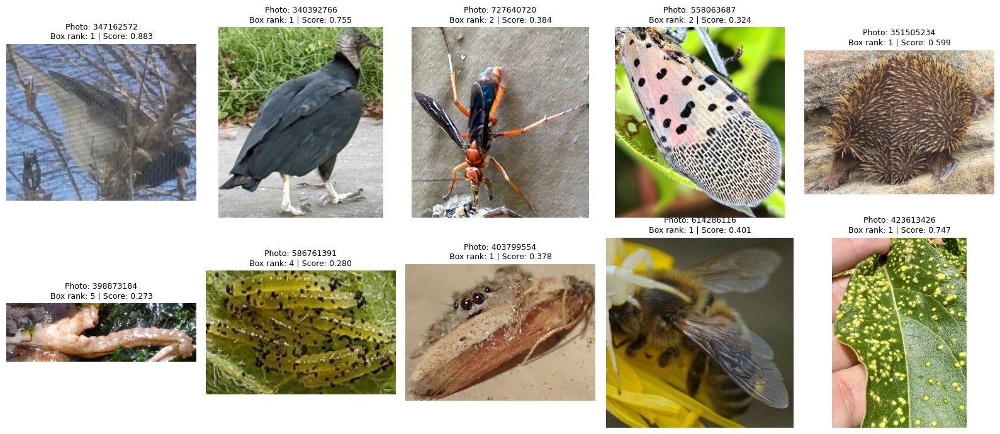

In [54]:
import matplotlib.pyplot as plt
from PIL import Image

# Select 10 detections
df_sample = df_boxes.sample(n=10, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, (_, row) in zip(axes.flat, df_sample.iterrows()):

    with Image.open(row["local_file_path"]) as img:
        img = img.convert("RGB")

        crop = img.crop((
            int(row["crop_x0"]),
            int(row["crop_y0"]),
            int(row["crop_x1"]),
            int(row["crop_y1"])
        ))

        ax.imshow(crop)
        ax.set_title(
            f"Photo: {row['photo_id']}\n"
            f"Box rank: {row['rank']} | Score: {row['score']:.3f}",
            fontsize=9
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

## Prepare BioCLIP2 zero-shot classification

In [2]:
import os
from pathlib import Path

import torch
import open_clip
from PIL import Image

CACHE_DIR = Path(
    "/rs1/researchers/a/amallav/species_classification/"
    "ecological_informatics/models/_hf_cache"
)

MODEL_SPEC = "hf-hub:imageomics/bioclip-2"

os.environ["HF_HOME"] = str(CACHE_DIR)
os.environ["HF_HUB_CACHE"] = str(CACHE_DIR / "hub")
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMER_OFFLINE"]="1"

device = "cpu"

if torch.cuda.is_available():
    try:
        x = torch.ones(4, device="cuda")
        assert x.sum().item() == 4
        device = "cuda"
    except Exception as e:
        print("CUDA test failed:", e)

print("Device:", device)
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU capability:", torch.cuda.get_device_capability(0))

/usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
PyTorch: 2.5.1
CUDA version: 12.1
GPU: NVIDIA H200 NVL
GPU capability: (9, 0)


In [3]:
SNAPSHOTS_DIR = (
    CACHE_DIR
    / "hub/models--imageomics--bioclip-2/snapshots"
)
snapshots = sorted(SNAPSHOTS_DIR.glob("*"))

for snapshot in snapshots:
    print("\nSnapshot:", snapshot)
    for file in snapshot.iterdir():
        print(file.name, "exists:", file.exists())


Snapshot: /rs1/researchers/a/amallav/species_classification/ecological_informatics/models/_hf_cache/hub/models--imageomics--bioclip-2/snapshots/715f34be0bcaa6f790b682d0fb010211e8f62c6c
special_tokens_map.json exists: True
open_clip_pytorch_model.bin exists: True
merges.txt exists: True
open_clip_model.safetensors exists: True
tokenizer_config.json exists: True
open_clip_config.json exists: True
README.md exists: True
tokenizer.json exists: True
vocab.json exists: True
.gitattributes exists: True


In [4]:
# Load BioCLIP2
import open_clip

MODEL_DIR = snapshots[0]

assert (MODEL_DIR / "open_clip_config.json").is_file(), \
    "OpenCLIP config is missing"

model, _, preprocess = open_clip.create_model_and_transforms(
    f"local-dir:{MODEL_DIR}"
)

tokenizer = open_clip.get_tokenizer(
    f"local-dir:{MODEL_DIR}"
)

model = model.to(device).eval()

print("BioCLIP2 loaded successfully")
print("Device:", device)

BioCLIP2 loaded successfully
Device: cuda


Image embedding shape: torch.Size([1, 768])
Embedding norm: 0.9999998807907104


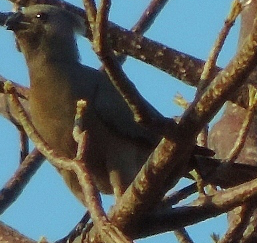

In [9]:
# Test one GroundingDINO crop
row = df_boxes.iloc[0]

with Image.open(row["local_file_path"]) as img:
    img = img.convert("RGB")

    crop = img.crop((
        int(row["crop_x0"]),
        int(row["crop_y0"]),
        int(row["crop_x1"]),
        int(row["crop_y1"])
    ))

image_tensor = preprocess(crop).unsqueeze(0).to(device)

with torch.inference_mode():
    image_features = model.encode_image(image_tensor)
    image_features = torch.nn.functional.normalize(
        image_features, dim=-1
    )

print("Image embedding shape:", image_features.shape)
print("Embedding norm:", image_features.norm(dim=-1).item())

display(crop)

In [10]:
# Check BioCLIP2's taxonomy vocabulary
import json

config_path = MODEL_DIR / "open_clip_config.json"

with open(config_path) as f:
    config = json.load(f)

print("Configuration keys:", config.keys())
print("Text configuration:")
print(config.get("model_cfg", {}).get("text_cfg", {}))

Configuration keys: dict_keys(['model_cfg', 'preprocess_cfg'])
Text configuration:
{'context_length': 77, 'vocab_size': 49408, 'width': 768, 'heads': 12, 'layers': 12}


In [11]:
import importlib.metadata

try:
    print("pybioclip:", importlib.metadata.version("pybioclip"))
except importlib.metadata.PackageNotFoundError:
    print("pybioclip not installed")

pybioclip: 2.1.1


In [17]:
EMB_PATH = TOL_DIR / "embeddings" / "txt_emb_bioclip-2.npy"
LABEL_PATH = TOL_DIR / "embeddings" / "txt_emb_bioclip-2.json"

print(EMB_PATH.exists(), LABEL_PATH.exists())

True True


In [20]:
# Load the taxonomy embeddings
import numpy as np
import json

# Load the precomputed embeddings without copying them all into RAM
text_embeddings = np.load(EMB_PATH, mmap_mode="r")
text_embeddings = text_embeddings.T

with open(LABEL_PATH, "r") as f:
    taxon_labels = json.load(f)

print("Text embedding shape:", text_embeddings.shape)
print("Number of taxonomic labels:", len(taxon_labels))
print("First label:", taxon_labels[0])

assert text_embeddings.shape[0] == len(taxon_labels)
assert text_embeddings.shape[1] == image_features.shape[1]

Text embedding shape: (867455, 768)
Number of taxonomic labels: 867455
First label: [['Animalia', '', '', '', '', 'Acanthodes', 'pristis'], '']


## Run zero-shot identification on one crop

In [21]:
import torch
import torch.nn.functional as F

TOP_K = 5
CHUNK_SIZE = 20000

best_scores = None
best_indices = None


In [22]:

with torch.inference_mode():

    for start in range(0, len(text_embeddings), CHUNK_SIZE):

        end = min(start + CHUNK_SIZE, len(text_embeddings))

        text_batch = torch.as_tensor(
            text_embeddings[start:end].copy(),
            dtype=torch.float32,
            device=device
        )

        text_batch = F.normalize(text_batch, dim=-1)

        similarities = image_features.float() @ text_batch.T

        scores, indices = similarities.topk(
            min(TOP_K, end - start), dim=1
        )

        indices += start

        if best_scores is None:
            best_scores = scores
            best_indices = indices
        else:
            combined_scores = torch.cat(
                [best_scores, scores], dim=1
            )
            combined_indices = torch.cat(
                [best_indices, indices], dim=1
            )

            best_scores, positions = combined_scores.topk(
                TOP_K, dim=1
            )

            best_indices = combined_indices.gather(
                1, positions
            )


In [23]:

top_scores = best_scores[0].cpu().tolist()
top_indices = best_indices[0].cpu().tolist()


In [24]:

for rank, (idx, score) in enumerate(
    zip(top_indices, top_scores), start=1
):
    names, common_name = taxon_labels[idx]

    species = f"{names[-2]} {names[-1]}"

    print(
        f"{rank}. {species} | "
        f"Similarity: {score:.4f} | "
        f"Common name: {common_name}"
    )

1. Corythaixoides concolor | Similarity: 0.7552 | Common name: Grey go-away-bird
2. Lamprotornis unicolor | Similarity: 0.7217 | Common name: Ashy Starling
3. Colius striatus | Similarity: 0.7116 | Common name: Speckled Mousebird
4. Poicephalus rueppellii | Similarity: 0.7107 | Common name: Rüppell's Parrot
5. Coua verreauxi | Similarity: 0.7102 | Common name: Verreaux's coua


## Final full bioclip2 run

In [27]:
#Configuration and checks
from pathlib import Path
import json
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from tqdm.auto import tqdm

# Configuration
BATCH_SIZE = 32
TOP_K = 5
CHUNK_SIZE = 20_000


In [30]:
OUTPUT_DIR = (
    PROJECT_PATH / "notebooks" / "interaction"/ "bioclip2" /"full_run"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [31]:
assert device == "cuda", "CUDA is required for this run"

model = model.to(device).eval()

# Taxonomy embeddings: expected (867455, 768)
# Handle either original or transposed orientation.
if text_embeddings.shape[0] != len(taxon_labels):
    assert text_embeddings.shape[1] == len(taxon_labels)
    text_embeddings = text_embeddings.T

assert text_embeddings.shape[0] == len(taxon_labels)

# Transfer normalized taxonomy embeddings to GPU once.
# float32 preserves consistency with the single-crop test.
text_gpu = torch.empty(
    text_embeddings.shape,
    dtype=torch.float32,
    device=device
)


In [32]:

with torch.inference_mode():
    for start in tqdm(
        range(0, len(text_embeddings), CHUNK_SIZE),
        desc="Loading taxonomy embeddings"
    ):
        end = min(start + CHUNK_SIZE, len(text_embeddings))

        chunk = np.ascontiguousarray(
            text_embeddings[start:end],
            dtype=np.float32
        )

        text_gpu[start:end] = torch.from_numpy(chunk).to(device)

    text_gpu = F.normalize(text_gpu, dim=1)

print("BioCLIP2 device:", device)
print("Taxonomy embeddings:", text_gpu.shape)
print("GroundingDINO detections:", len(df_boxes))

Loading taxonomy embeddings: 100%|█████████████████████████████████████████████████████████████████████████████| 44/44 [00:00<00:00, 79.47it/s]

BioCLIP2 device: cuda
Taxonomy embeddings: torch.Size([867455, 768])
GroundingDINO detections: 18145


In [33]:
# Crop preparation function
def prepare_crop(row):
    """
    Load a validated GroundingDINO crop and
    apply BioCLIP2 image preprocessing.
    """

    with Image.open(row["local_file_path"]) as img:
        img = img.convert("RGB")

        crop = img.crop((
            int(row["crop_x0"]),
            int(row["crop_y0"]),
            int(row["crop_x1"]),
            int(row["crop_y1"])
        ))

        return preprocess(crop)

In [34]:
# BioCLIP2 inference function
def predict_bioclip_batch(batch_df):
    """
    Zero-shot BioCLIP2 inference.

    Returns:
        predictions: list of prediction dictionaries
        errors: list of failed crop dictionaries
    """

    images = []
    valid_indices = []
    errors = []

    # Load crops
    for source_idx, row in batch_df.iterrows():
        try:
            image_tensor = prepare_crop(row)

            images.append(image_tensor)
            valid_indices.append(source_idx)

        except Exception as e:
            errors.append({
                "source_index": source_idx,
                "model_status": "error",
                "model_error": str(e)
            })

    if not images:
        return [], errors

    batch_tensor = torch.stack(images).to(device)

    # BioCLIP2 inference
    with torch.inference_mode():

        image_features_batch = model.encode_image(
            batch_tensor
        )

        image_features_batch = F.normalize(
            image_features_batch.float(),
            dim=-1
        )

        similarities = image_features_batch @ text_gpu.T

        scores, indices = torch.topk(
            similarities,
            k=TOP_K,
            dim=1
        )

        scores = scores.cpu().numpy()
        indices = indices.cpu().numpy()

    predictions = []

    # Convert predictions into records
    for i, source_idx in enumerate(valid_indices):

        for pred_rank in range(TOP_K):

            taxon_idx = int(indices[i, pred_rank])
            score = float(scores[i, pred_rank])

            names, common_name = taxon_labels[taxon_idx]

            genus = names[5]
            species_epithet = names[6]

            species_name = (
                f"{genus} {species_epithet}"
                if genus and species_epithet
                else None
            )

            predictions.append({
                "source_index": source_idx,

                "model_prediction_rank": pred_rank + 1,
                "model_taxon_index": taxon_idx,
                "model_score": score,

                "model_kingdom_name": names[0],
                "model_phylum_name": names[1],
                "model_class_name": names[2],
                "model_order_name": names[3],
                "model_family_name": names[4],
                "model_genus_name": genus,
                "model_species_epithet": species_epithet,
                "model_species_name": species_name,
                "model_common_name": common_name,

                "model_status": "success",
                "model_error": None,
            })

    return predictions, errors

In [ ]:
# Preserve original dataframe and column names
df_run = df_boxes.reset_index(drop=True).copy()

all_predictions = []
all_errors = []

for start in tqdm(
    range(0, len(df_run), BATCH_SIZE),
    desc="BioCLIP2 full inference"
):

    end = min(start + BATCH_SIZE, len(df_run))

    batch_df = df_run.iloc[start:end]

    predictions, errors = predict_bioclip_batch(
        batch_df
    )

    all_predictions.extend(predictions)
    all_errors.extend(errors)

df_predictions = pd.DataFrame(all_predictions)

df_errors = pd.DataFrame(
    all_errors,
    columns=[
        "source_index",
        "model_status",
        "model_error"
    ]
)

print("Total input detections:", len(df_run))
print(
    "Successfully processed detections:",
    df_predictions["source_index"].nunique()
)
print("Failed detections:", len(df_errors))
print("Prediction rows:", len(df_predictions))

### Create per-box export

In [ ]:
# Preserve all original source columns
df_source = df_run.reset_index(names="source_index")


In [ ]:

# Combine predictions with original data
df_per_box = df_source.merge(
    df_predictions,
    on="source_index",
    how="left",
    validate="one_to_many"
)


In [ ]:

# Populate failed crop information
if not df_errors.empty:

    error_lookup = df_errors.set_index(
        "source_index"
    )["model_error"]

    failed_mask = df_per_box["model_status"].isna()

    df_per_box.loc[
        failed_mask, "model_status"
    ] = "error"

    df_per_box.loc[
        failed_mask, "model_error"
    ] = df_per_box.loc[
        failed_mask, "source_index"
    ].map(error_lookup)


In [ ]:

# Keep source columns first, model columns second
source_cols = df_boxes.columns.tolist()


In [ ]:

model_cols = [
    c for c in df_per_box.columns
    if c.startswith("model_")
]


In [ ]:

df_per_box = df_per_box[
    source_cols + model_cols
]


In [ ]:

# Export
PER_BOX_PATH = OUTPUT_DIR / "bioclip2_per_box.parquet"


In [ ]:

df_per_box.to_parquet(
    PER_BOX_PATH,
    index=False
)

print("Saved:", PER_BOX_PATH)
print("Rows:", len(df_per_box))
print("Columns:", len(df_per_box.columns))

### Create per-image export

In [ ]:
# Sort detections and predictions
df_per_image = (
    df_per_box
    .sort_values(
        [
            "photo_id",
            "rank",
            "model_prediction_rank"
        ],
        ascending=[True, True, True],
        na_position="last"
    )
    .drop_duplicates(
        subset=["photo_id"],
        keep="first"
    )
    .copy()
)


In [ ]:

# Keep original source columns unchanged.
# Add explicit selected-box metadata.
df_per_image["model_selected_box_rank"] = (
    df_per_image["rank"]
)


In [ ]:

df_per_image["model_selected_box_score"] = (
    df_per_image["score"]
)


In [ ]:

# Export
PER_IMAGE_PATH = (
    OUTPUT_DIR / "bioclip2_per_image.parquet"
)



In [ ]:
df_per_image.to_parquet(
    PER_IMAGE_PATH,
    index=False
)

print("Saved:", PER_IMAGE_PATH)
print("Images:", len(df_per_image))
print("Columns:", len(df_per_image.columns))

In [ ]:
# Final validation
# Input coverage
assert df_per_box[
    ["photo_id", "rank"]
].drop_duplicates().shape[0] == df_run[
    ["photo_id", "rank"]
].drop_duplicates().shape[0]


In [ ]:

# All original source columns preserved
assert set(df_boxes.columns).issubset(
    df_per_box.columns
)

assert set(df_boxes.columns).issubset(
    df_per_image.columns
)

# No duplicate image-level records
assert df_per_image["photo_id"].is_unique

# Successful detections have exactly TOP_K predictions
successful = df_per_box[
    df_per_box["model_status"] == "success"
]

counts = successful.groupby(
    ["photo_id", "rank"], dropna=False
).size()

assert counts.eq(TOP_K).all()

# All rows accounted for, including failed crops
successful_crops = df_predictions["source_index"].nunique()

assert (
    successful_crops + len(df_errors)
    == len(df_run)
)

assert (
    len(df_per_box)
    == successful_crops * TOP_K + len(df_errors)
)

print("Validation passed")

print("\nSource detections:", len(df_run))
print("Successful detections:", successful_crops)
print("Failed detections:", len(df_errors))
print("Per-box rows:", len(df_per_box))
print("Per-image rows:", len(df_per_image))

print("\nFinal files:")
print(PER_BOX_PATH)
print(PER_IMAGE_PATH)


In [ ]:

display(
    df_per_image[
        [
            "photo_id",
            "rank",
            "score",
            "model_prediction_rank",
            "model_species_name",
            "model_score",
            "model_status"
        ]
    ].head(10)
)

## Evaluate the results

In [3]:
import pandas as pd
df_bioclip_box_raw= pd.read_parquet("bioclip2/full_run/bioclip2_per_box.parquet")
df_bioclip_img_raw= pd.read_parquet("bioclip2/full_run/bioclip2_per_image.parquet")

In [4]:
df_bioclip_box_raw.shape

(90725, 66)

In [5]:
df_bioclip_img_raw.shape

(8614, 68)

In [6]:
df_bioclip_box_raw.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'box_clipped', 'crop_width', 'crop_height', 'crop_area_fraction',
       'model_prediction_rank', 'model_taxon_index', 'model_score',
       'model_kingdom_name', 'model_phylum_name', 'model_class_

In [7]:
df_bioclip_img_raw.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'box_clipped', 'crop_width', 'crop_height', 'crop_area_fraction',
       'model_prediction_rank', 'model_taxon_index', 'model_score',
       'model_kingdom_name', 'model_phylum_name', 'model_class_

In [8]:
df_bioclip_box_raw.drop(columns=["model_status","model_error"],inplace=True)

In [9]:
# Removed where the species name does not exist. Since without ground label it would be
df_bioclip_box = df_bioclip_box_raw.dropna(subset=["species_name"])
df_bioclip_img = df_bioclip_img_raw.dropna(subset=["species_name"])

In [10]:
df_bioclip_box.shape

(88610, 64)

In [11]:
df_bioclip_img.shape

(8409, 68)

### Rank level Match

In [12]:
ranks = [
    'kingdom',
    'phylum',
    'class',
    "order",
    "family",
    "genus",
    "species"
]

In [13]:
def rank_match(rank):
    match_col = f"{rank}_match"
    source_col = f"{rank}_name"
    model_col = f"model_{rank}_name"
    df_bioclip_box[match_col] = df_bioclip_box[source_col].astype(str) == df_bioclip_box[model_col].astype(str)
    print(f"Added {match_col} to the df_raw")
    if match_col in df_bioclip_box.columns: 
        print(f"{match_col} column exists ✔️")
    else:
        print(f"{match_col} column does not exist ❌")
    print("-"*20)

for rank in ranks:
    rank_match(rank)

Added kingdom_match to the df_raw
kingdom_match column exists ✔️
--------------------
Added phylum_match to the df_raw
phylum_match column exists ✔️
--------------------
Added class_match to the df_raw
class_match column exists ✔️
--------------------
Added order_match to the df_raw
order_match column exists ✔️
--------------------
Added family_match to the df_raw
family_match column exists ✔️
--------------------
Added genus_match to the df_raw
genus_match column exists ✔️
--------------------
Added species_match to the df_raw
species_match column exists ✔️
--------------------


In [14]:
# Image-level BioCLIP pipeline evaluation

def rank_level_accuracy(rank):
    match_col = f"{rank}_match"
    image_results = (
        df_bioclip_box.groupby("file_name")[match_col]
        .any()
        .reset_index(name="identified")
    )
    
    # Counts
    n_total = len(image_results)
    n_identified = image_results["identified"].sum()
    n_failed = n_total - n_identified
    
    print(f"{rank} level match")
    print(f"Total images:      {n_total}")
    print(f"Identified:        {n_identified}")
    print(f"Failed:            {n_failed}")
    print(f"Accuracy:          {n_identified / n_total:.4f}")
    print(f"Accuracy (%):      {100 * n_identified / n_total:.2f}%")
    print("----------------------------------------------------------------------------")


In [15]:
for rank in ranks:
    rank_level_accuracy(rank)

kingdom level match
Total images:      8409
Identified:        8380
Failed:            29
Accuracy:          0.9966
Accuracy (%):      99.66%
----------------------------------------------------------------------------
phylum level match
Total images:      8409
Identified:        8186
Failed:            223
Accuracy:          0.9735
Accuracy (%):      97.35%
----------------------------------------------------------------------------
class level match
Total images:      8409
Identified:        6748
Failed:            1661
Accuracy:          0.8025
Accuracy (%):      80.25%
----------------------------------------------------------------------------
order level match
Total images:      8409
Identified:        6340
Failed:            2069
Accuracy:          0.7540
Accuracy (%):      75.40%
----------------------------------------------------------------------------
family level match
Total images:      8409
Identified:        6582
Failed:            1827
Accuracy:          0.7827
Accurac

In [16]:
species_results = (
    df_bioclip_box.groupby("file_name")["species_match"]
    .any()
    .reset_index(name="species_identified")
)
df = pd.merge(df_bioclip_box, species_results[["file_name", "species_identified"]], on="file_name", how="left")

In [17]:
df_bioclip_box.shape

(88610, 71)

In [18]:
species_results.shape

(8409, 2)

In [19]:
df_bioclip_box["file_name"].nunique()

8409

## Error Handling

# Action Identification - VLM + Parser

In [20]:
df_success = df[df["species_identified"]==True]
df_success.shape

(55650, 72)

In [21]:
df_success["file_name"].nunique()

5213

## Getting the interaction dataset

In [22]:
## Check if there is any way to get the both A- to b and b to A pairs interactions only.
pairs = set(
    zip(
        df_success["observation_id"],
        df_success["partner_observation_id"]
    )
)

mask = [
    (partner, obs) in pairs
    for obs, partner in zip(
        df_success["observation_id"],
        df_success["partner_observation_id"]
    )
]

df_reciprocal = df_success[mask].copy()
df_reciprocal.shape

(20635, 72)

In [23]:
## Check whether there all the observations id exists in the partner observation id columns and viceversa
reciprocal_obs =  df_reciprocal["observation_id"].unique()
partner_obs = df_reciprocal["partner_observation_id"].unique()

if set(reciprocal_obs) == set(partner_obs):
    print("relationship if both directions explicitly occur - ✅")
else:
    print("There are interaction edges where both directions do not occur- ❌")

relationship if both directions explicitly occur - ✅


In [24]:
## check for interaction edges where Both observations simply exist
obs_list = df_success["observation_id"].to_list()
df_partner_exists = df_success[df_success["partner_observation_id"].isin(obs_list)]
df_partner_exists.shape

(21255, 72)

In [25]:
## Check whether there all the observations id exists in the partner observation id columns and viceversa
reciprocal_obs =  df_partner_exists["observation_id"].unique()
partner_obs = df_partner_exists["partner_observation_id"].unique()

if set(reciprocal_obs) == set(partner_obs):
    print("relationship if both directions explicitly occur - ✅")
else:
    print("There are interaction edges where both directions do not occur- ❌")

There are interaction edges where both directions do not occur- ❌


In [26]:
## Looking for interactions where both sides dont occur
no_reciprocal_edges = df_partner_exists[
    ~df_partner_exists.index.isin(df_reciprocal.index)
].copy()

print("Partner exists:", len(df_partner_exists))
print("Non-reciprocal edges:", len(no_reciprocal_edges))

display(no_reciprocal_edges)

Partner exists: 21255
Non-reciprocal edges: 620


,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,model_species_name,model_common_name,kingdom_match,phylum_match,class_match,order_match,family_match,genus_match,species_match,species_identified
7950,137293405,234454061,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/13729...,137288684,https://www.inaturalist.org/observations/13728...,Lynx rufus,species,cc-by-nc,...,Prionailurus rubiginosus,Rusty-spotted cat,True,True,True,True,True,False,False,True
7951,137293405,234454061,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/13729...,137288684,https://www.inaturalist.org/observations/13728...,Lynx rufus,species,cc-by-nc,...,Lynx rufus,Bobcat,True,True,True,True,True,True,True,True
7952,137293405,234454061,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/13729...,137288684,https://www.inaturalist.org/observations/13728...,Lynx rufus,species,cc-by-nc,...,Leopardus braccatus,Pantanal cat,True,True,True,True,True,False,False,True
7953,137293405,234454061,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/13729...,137288684,https://www.inaturalist.org/observations/13728...,Lynx rufus,species,cc-by-nc,...,Lynx canadensis,Canada Lynx,True,True,True,True,True,True,False,True
7954,137293405,234454061,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/13729...,137288684,https://www.inaturalist.org/observations/13728...,Lynx rufus,species,cc-by-nc,...,Catopuma temminckii,Asian golden cat,True,True,True,True,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85730,86345500,142227030,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/86345500,86345495,https://www.inaturalist.org/observations/86345495,Apodichthys flavidus,species,cc-by-nc,...,Elysia chlorotica,Eastern emerald elysia,True,False,False,False,False,False,False,True
85731,86345500,142227030,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/86345500,86345495,https://www.inaturalist.org/observations/86345495,Apodichthys flavidus,species,cc-by-nc,...,Apodichthys flavidus,Penpoint gunnel,True,True,False,True,True,True,True,True
85732,86345500,142227030,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/86345500,86345495,https://www.inaturalist.org/observations/86345495,Apodichthys flavidus,species,cc-by-nc,...,Petromyzon marinus,Sea lamprey,True,True,False,False,False,False,False,True
85733,86345500,142227030,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/86345500,86345495,https://www.inaturalist.org/observations/86345495,Apodichthys flavidus,species,cc-by-nc,...,Acyrtops beryllinus,Emerald clingfish,True,True,False,False,False,False,False,True


Classify them to understand why the reverse relationship is missing.

For example, A → B exists, but B → A does not. There could be several explanations:
1. B does not exist in the dataset: The partner observation was never imported.
2. B exists but has no partner ID: Its partner_observation_id is missing.
3. B points to C: The reverse relationship is absent because B references a different observation.
4. B points to multiple observations, but not A: B has several interaction rows, yet none links back to A.
5. B points to itself: Potentially an incorrect self-reference.
6. B has duplicate or conflicting records: Multiple rows associated with B need investigation.

Leaving out point 1 because we already have created df_partner_exists in the same way

In [27]:
obs_col = "observation_id"
partner_col = "partner_observation_id"

df_review = df_success.copy()

In [28]:
# Ensure IDs are comparable (assuming numeric observation IDs)
df_review[obs_col] = pd.to_numeric(df_review[obs_col], errors="coerce").astype("Int64")
df_review[partner_col] = pd.to_numeric(df_review[partner_col], errors="coerce").astype("Int64")

In [29]:
# All observation IDs and directed relationships
obs_ids = set(df_review[obs_col].dropna())
pairs = set(
    df_review[[obs_col, partner_col]]
    .dropna()
    .itertuples(index=False, name=None)
)

In [30]:
# Partner IDs for each observation
partner_map = (
    df_review.groupby(obs_col)[partner_col]
    .agg(lambda x: set(x.dropna()))
    .to_dict()
)


In [31]:
# Classify each row
def classify_interaction(row):
    a = row[obs_col]
    b = row[partner_col]

    if pd.isna(a):
        return "Invalid observation ID"

    if pd.isna(b):
        return "Missing partner ID"

    if a == b:
        return "Self-reference"

    if b not in obs_ids:
        return "Partner observation absent"

    if (b, a) in pairs:
        return "Reciprocal"

    b_partners = partner_map.get(b, set())

    if len(b_partners) == 0:
        return "B exists, no partner ID"

    if b_partners == {b}:
        return "B points to itself"

    if len(b_partners) == 1:
        return "B points to another observation"

    return "B points to multiple other observations"


df_review["interaction_case"] = df_review.apply(
    classify_interaction, axis=1
)

In [32]:
case_summary = (
    df_review["interaction_case"]
    .value_counts(dropna=False)
    .rename_axis("interaction_case")
    .reset_index(name="row_count")
)

case_summary["percentage"] = (
    100 * case_summary["row_count"] / len(df_review)
).round(2)

display(case_summary)


,interaction_case,row_count,percentage
0,Partner observation absent,34395,61.81
1,Reciprocal,20105,36.13
2,Self-reference,530,0.95
3,B points to another observation,335,0.60
4,B points to itself,285,0.51


In [33]:
case_summary["row_count"].sum()

np.int64(55650)

In [34]:
df_review.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'box_clipped', 'crop_width', 'crop_height', 'crop_area_fraction',
       'model_prediction_rank', 'model_taxon_index', 'model_score',
       'model_kingdom_name', 'model_phylum_name', 'model_class_

> For now for the convenience of evaluation of the pipeline, I am for now going ahead with interactions with stricter reciprocals and no self rederence i.e A -> B and B-> A interaction edges should be present, but no self reference.

In [35]:
df_review["interaction_case"].value_counts()

interaction_case
Partner observation absent         34395
Reciprocal                         20105
Self-reference                       530
B points to another observation      335
B points to itself                   285
Name: count, dtype: int64

In [36]:
df_inter = df_review[df_review["interaction_case"] == "Reciprocal" ]
df_inter.shape

(20105, 73)

## Create test data for the rest of the pipeline plausibility

### For test evaluation - I am focusing on chordata phylum interaction edges.

In [37]:
df_inter["file_name"].nunique()

1679

In [38]:
df_inter["phylum_name"].unique()

<ArrowStringArray>
[       'Chordata',      'Arthropoda',   'Echinodermata',        'Mollusca',
        'Annelida',        'Cnidaria', 'Platyhelminthes']
Length: 7, dtype: str

In [39]:
chordata = df_inter[df_inter["phylum_name"]== 'Chordata']
chordata.shape

(10260, 73)

In [40]:
chordata["phylum_name"].unique()

<ArrowStringArray>
['Chordata']
Length: 1, dtype: str

In [41]:
chordata = chordata.sample(frac=1)

In [42]:
# Get all valid directed pairs
pairs = set(
    chordata[[obs_col, partner_col]]
    .dropna()
    .itertuples(index=False, name=None)
)
len(pairs)

382

In [43]:
# Find unique reciprocal pairs
reciprocal_pairs = {
    tuple(sorted((a, b)))
    for a, b in pairs
    if a != b and (b, a) in pairs
}
len(reciprocal_pairs)

153

In [44]:
# Select 10 reciprocal pairs
selected_pairs = list(sorted(reciprocal_pairs))[:10]
selected_pairs

[(np.int64(893936), np.int64(894002)),
 (np.int64(1059442), np.int64(1059454)),
 (np.int64(4706757), np.int64(4706758)),
 (np.int64(7362330), np.int64(7363759)),
 (np.int64(8095014), np.int64(8095016)),
 (np.int64(8141947), np.int64(28851083)),
 (np.int64(15338360), np.int64(15338361)),
 (np.int64(19501897), np.int64(19501898)),
 (np.int64(25189764), np.int64(25191260)),
 (np.int64(34861833), np.int64(34861851))]

In [45]:
# Include both directions
selected_edges = {
    edge
    for a, b in selected_pairs
    for edge in [(a, b), (b, a)]
}


In [46]:
# Extract original rows for those edges
mask = [
    (a, b) in selected_edges
    for a, b in zip(
        chordata[obs_col],
        chordata[partner_col]
    )
]

df_test = chordata.loc[mask].copy()
df_test.shape

(370, 73)

In [47]:
print("Unique reciprocal pairs:", len(selected_pairs))
print("Rows selected:", len(df_test))

display(df_test[[obs_col, partner_col]])

Unique reciprocal pairs: 10
Rows selected: 370


,observation_id,partner_observation_id
40393,25191260,25189764
2042,1059454,1059442
83492,7363759,7362330
85083,8141947,28851083
86380,893936,894002
...,...,...
83482,7363759,7362330
83440,7362330,7363759
86383,893936,894002
62698,34861833,34861851


In [48]:
# Check whether there are any interaction edge where there is not reverse interaction edge.
obs_col = "observation_id"
partner_col = "partner_observation_id"

temp = df_test.copy()

# Build all reference structures from df_test
obs_ids = set(temp[obs_col].dropna())

pairs = set(
    temp[[obs_col, partner_col]]
    .dropna()
    .itertuples(index=False, name=None)
)

partner_map = (
    temp.groupby(obs_col)[partner_col]
    .agg(lambda x: set(x.dropna()))
    .to_dict()
)

# Apply classification
temp["interaction_case"] = temp.apply(
    classify_interaction,
    axis=1
)

testcase_summary = (
    temp["interaction_case"]
    .value_counts(dropna=False)
    .rename_axis("interaction_case")
    .reset_index(name="row_count")
)

testcase_summary["percentage"] = (
    100 * testcase_summary["row_count"] / len(temp)
).round(2)

display(testcase_summary)


,interaction_case,row_count,percentage
0,Reciprocal,370,100.0


In [49]:
df_test.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'box_clipped', 'crop_width', 'crop_height', 'crop_area_fraction',
       'model_prediction_rank', 'model_taxon_index', 'model_score',
       'model_kingdom_name', 'model_phylum_name', 'model_class_

In [50]:
raw_copy = df_test.copy()

In [51]:
# Removing duplicate photo_id rows
df_test.sort_values(by="rank", inplace=True)
df_test = df_test[df_test.duplicated(subset=["photo_id"],keep ='first')]
df_test.sort_values(
    by=["observation_id", "crop_area_fraction"],
    ascending=[True, False],
    inplace=True
)
df_test = df_test.drop_duplicates(
    subset="observation_id",
    keep="first"
)
df_test.shape

(20, 73)

In [52]:
import os
df_test.to_csv("test_dataset_action.csv", index=False)
print(f" ✅ test_dataset_action.csv saved successfully in the {os.getcwd()}")

 ✅ test_dataset_action.csv saved successfully in the /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/interaction


## Setting up the VLM

### Install the Qwen3-VL-8B-Instruct

In [53]:
# Check your existing environment
import sys
import torch
import transformers
import importlib.util

print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
    print("GPU capability:", torch.cuda.get_device_capability(0))

for package in ["accelerate", "huggingface_hub", "qwen_vl_utils"]:
    print(f"{package} installed:", importlib.util.find_spec(package) is not None)

/usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.9
Executable: /usr/local/usrapps/ftrscape/snair3/env_AiPipeline/bin/python
PyTorch: 2.5.1
Transformers: 5.3.0
CUDA available: True
GPU: NVIDIA H200 NVL
GPU memory (GB): 139.79
GPU capability: (9, 0)
accelerate installed: True
huggingface_hub installed: True
qwen_vl_utils installed: False


### Load Qwen3-VL into your notebook

In [54]:
import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

MODEL_DIR = (
    "/rs1/researchers/a/amallav/"
    "species_classification/ecological_informatics/"
    "models/Qwen3-VL-8B-Instruct"
)

# Load model from local storage
model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_DIR,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="sdpa",
    local_files_only=True
)

# Load processor
processor = AutoProcessor.from_pretrained(
    MODEL_DIR,
    local_files_only=True
)

model.eval()

print("Model loaded successfully")
print("Device:", model.device)
print("Model dtype:", model.dtype)
print(
    "GPU memory allocated (GB):",
    round(torch.cuda.memory_allocated() / 1024**3, 2)
)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████| 750/750 [00:09<00:00, 79.13it/s]


Model loaded successfully
Device: cuda:0
Model dtype: torch.bfloat16
GPU memory allocated (GB): 16.33


### Test action description on one image

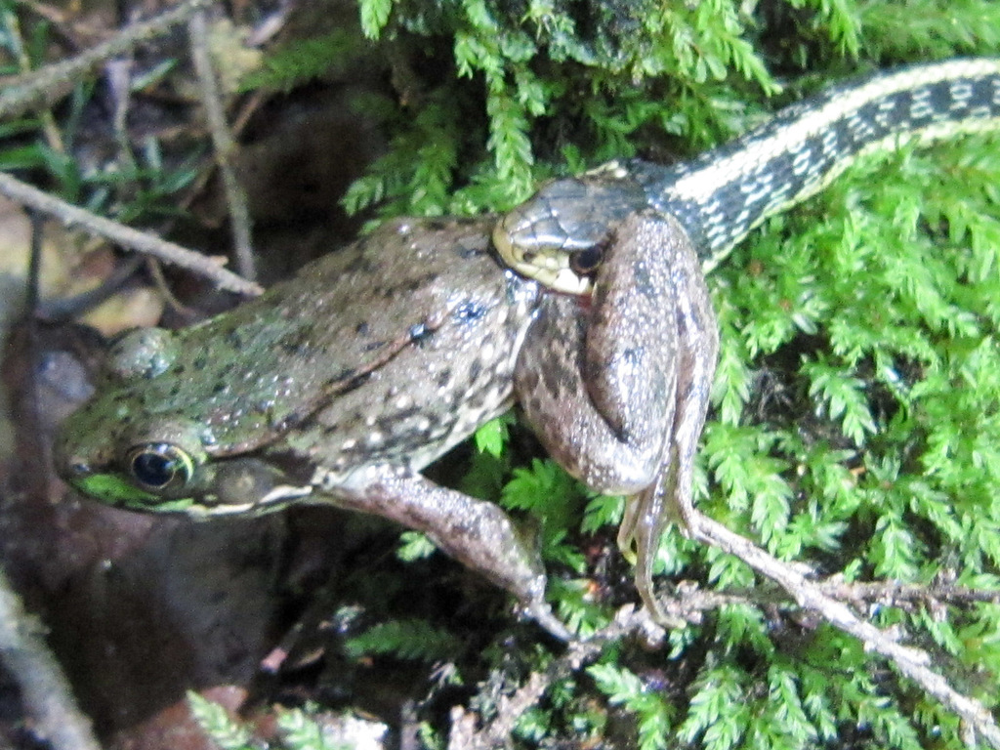

In [71]:
from PIL import Image
from IPython.display import display

row = df_test.iloc[4]

image_path = row["local_file_path"]
common_name = row["model_common_name"]

image = Image.open(image_path).convert("RGB")
display(image)

In [81]:
df_test.columns

Index(['observation_id', 'photo_id', 'photo_license_code', 'photo_url',
       'obs_url', 'partner_observation_id', 'partner_observation_url',
       'scientific_name', 'taxon_rank', 'observation_license_code',
       'predator_prey_role', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'kingdom_name', 'phylum_name', 'class_name',
       'order_name', 'family_name', 'genus_name', 'species_name',
       'valid_partner', 'file_name', 'file_exists', 'local_file_path',
       'grounding_dino_prompt', 'source_row', 'rank', 'score', 'text_label',
       'x0', 'y0', 'x1', 'y1', 'img_width', 'img_height', 'gd_num_boxes',
       'gd_status', 'box_width', 'box_height', 'box_area_frac', 'aspect_ratio',
       'center_offset_frac', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1',
       'box_clipped', 'crop_width', 'crop_height', 'crop_area_fraction',
       'model_prediction_rank', 'model_taxon_index', 'model_score',
       'model_kingdom_name', 'model_phylum_name', 'model_class_

In [84]:
# Generate action description
common_name = df_test.iloc[4]["model_common_name"]
scientific_name = df_test.iloc[4]["model_species_name"]
scientific_name, common_name

('Thamnosophis epistibes', '')

In [85]:

prompt = f"""
You are analyzing an ecological observation image.

The target organism is identified as: 
scientific name = "{scientific_name}
common name= "{common_name}".

Your task is to describe the visible action, behavior, and physical
condition of this target organism from its perspective.

Focus specifically on:
- What the target organism appears to be doing.
- Whether it is feeding on, attacking, grasping, carrying, or
  otherwise interacting with another organism.
- Whether another organism appears to be feeding on, attacking,
  grasping, carrying, or restraining the target organism.
- Whether the target appears inactive, injured, trapped, or
  potentially dead, but only when supported by visible evidence.

Important rules:
1. Focus on the target organism, not the overall scene.
2. Use the provided common name only to identify the target.
   Do not assume its behavior based on its species or identity.
3. Describe only what is visually supported by the image.
4. Distinguish between an action performed BY the target organism
   and an action performed ON the target organism.
5. Do not infer death merely because the organism is motionless.
6. If the target organism cannot be confidently located or its
   action is unclear, explicitly state this.
7. Do not invent ecological relationships.

Respond in one or two concise sentences describing the target
organism's action or condition.
"""

In [86]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }
]


In [87]:
inputs = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device)



In [88]:
with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False
    )

generated_ids = generated_ids[
    :, inputs["input_ids"].shape[1]:
]

description = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0].strip()

print("Target organism:", common_name)
print("Qwen3-VL Action Description:")
print(description)


Target organism: 
Qwen3-VL Action Description:
The target organism, a Thamnosophis epistibes, appears to be actively grasping or holding onto another frog with its mouth, likely in a predatory or defensive interaction. There is no visible evidence to suggest it is injured, trapped, or dead.


In [89]:
df_test.iloc[4]["common_name"]

'Common Garter Snake'

## Run inference on the dataframe

In [90]:
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# Configuration
IMAGE_COL = "local_file_path"
OUTPUT_COL = "vlm_action_description"

In [91]:

# Work on a copy to preserve the original dataframe
df_vlm = df_test.copy().reset_index(drop=True)


In [92]:

descriptions = []
errors = []

model.eval()

for _, row in tqdm(
    df_vlm.iterrows(),
    total=len(df_vlm),
    desc="Qwen3-VL inference"
):
    try:
        image_path = row[IMAGE_COL]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": image},
                    {"type": "text", "text": prompt},
                ],
            }
        ]

        inputs = processor.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt"
        ).to(model.device)

        with torch.inference_mode():
            generated_ids = model.generate(
                **inputs,
                max_new_tokens=100,
                do_sample=False
            )

        generated_ids = generated_ids[
            :, inputs["input_ids"].shape[1]:
        ]

        description = processor.batch_decode(
            generated_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()

        descriptions.append(description)
        errors.append(None)

        del inputs, generated_ids

    except Exception as e:
        descriptions.append(None)
        errors.append(str(e))

# Add results to dataframe
df_vlm[OUTPUT_COL] = descriptions
df_vlm["vlm_error"] = errors

print("Total images:", len(df_vlm))
print("Successful:", df_vlm[OUTPUT_COL].notna().sum())
print("Failed:", df_vlm["vlm_error"].notna().sum())

Qwen3-VL inference: 100%|██████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:14<00:00,  1.36it/s]

Total images: 20
Successful: 20
Failed: 0


In [93]:
from pathlib import Path

current_path = Path.cwd()
out_vlm_dir = current_path / "action_description"

out_vlm_dir.mkdir(exist_ok=True)




In [94]:
df_vlm_path = out_vlm_dir / "test_action_vlm.csv"
df_vlm.to_csv(df_vlm_path, index=False)

# Action Identification - RelateAnything

In [2]:
import pandas as pd
df_test = pd.read_csv("test_dataset_action.csv")
df_test.shape

(20, 73)

In [3]:
df_test.head()

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,model_common_name,kingdom_match,phylum_match,class_match,order_match,family_match,genus_match,species_match,species_identified,interaction_case
0,893936,1136774,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/893936,894002,https://www.inaturalist.org/observations/894002,Lycaon pictus pictus,subspecies,cc-by,...,African wild dog,True,True,True,True,True,True,True,True,Reciprocal
1,894002,1136901,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/894002,893936,https://www.inaturalist.org/observations/893936,Necrosyrtes monachus,species,cc-by,...,Lappet-faced vulture,True,True,True,True,True,False,False,True,Reciprocal
2,1059442,1328444,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/1059442,1059454,https://www.inaturalist.org/observations/1059454,Syncerus caffer caffer,subspecies,cc-by,...,Muskox,True,True,True,True,True,False,False,True,Reciprocal
3,1059454,1328462,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/1059454,1059442,https://www.inaturalist.org/observations/1059442,Panthera leo melanochaita,subspecies,cc-by,...,African golden wolf,True,True,True,True,False,False,False,True,Reciprocal
4,4706757,5695459,cc0,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/4706757,4706758,https://www.inaturalist.org/observations/4706758,Thamnophis sirtalis,species,cc0,...,NaN,True,True,False,False,False,False,False,True,Reciprocal


## Setup RelateAnything

# Draw final interaction conclusion

In [95]:
import pandas as pd
df_vlm = pd.read_csv(out_vlm_dir /"test_action_vlm.csv")
df_vlm.head()

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,phylum_match,class_match,order_match,family_match,genus_match,species_match,species_identified,interaction_case,vlm_action_description,vlm_error
0,893936,1136774,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/893936,894002,https://www.inaturalist.org/observations/894002,Lycaon pictus pictus,subspecies,cc-by,...,True,True,True,True,True,True,True,Reciprocal,"The target organism, a wild dog, is lying on i...",NaN
1,894002,1136901,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/894002,893936,https://www.inaturalist.org/observations/893936,Necrosyrtes monachus,species,cc-by,...,True,True,True,True,False,False,True,Reciprocal,"The target organism, a wild dog, is standing a...",NaN
2,1059442,1328444,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/1059442,1059454,https://www.inaturalist.org/observations/1059454,Syncerus caffer caffer,subspecies,cc-by,...,True,True,True,True,False,False,True,Reciprocal,"The target organism, a small, light-colored an...",NaN
3,1059454,1328462,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/1059454,1059442,https://www.inaturalist.org/observations/1059442,Panthera leo melanochaita,subspecies,cc-by,...,True,True,True,False,False,False,True,Reciprocal,"The target organism, a small, light-colored an...",NaN
4,4706757,5695459,cc0,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/4706757,4706758,https://www.inaturalist.org/observations/4706758,Thamnophis sirtalis,species,cc0,...,True,False,False,False,False,False,True,Reciprocal,"The target organism, a Thamnosophis epistibes,...",NaN


## Method 1: Rule-based semantic parser

In [96]:

import re
import pandas as pd

In [97]:
# Define feeding patterns - need to add more
import re

# ---------------------------------------------------------
# 1. DIRECT FEEDING
# Strong evidence of active consumption
# ---------------------------------------------------------

FEEDING = [
    # Eating
    r"\b(?:eat|eats|eating|ate)\b",
    r"\b(?:feed|feeds|feeding|fed)\s+(?:on|upon)\b",
    r"\b(?:prey|preys|preying|preyed)\s+(?:on|upon)\b",

    # Consumption
    r"\b(?:consume|consumes|consuming|consumed)\b",
    r"\b(?:devour|devours|devouring|devoured)\b",
    r"\b(?:ingest|ingests|ingesting|ingested)\b",

    # Swallowing
    r"\b(?:swallow|swallows|swallowing|swallowed)\b",
    r"\b(?:gulp|gulps|gulping|gulped)\s+(?:down|up)?\b",
    r"\b(?:gobble|gobbles|gobbling|gobbled)\s+(?:up|down)?\b",

    # Chewing / consuming flesh
    r"\b(?:chew|chews|chewing|chewed)\s+(?:on|up)?\b",
    r"\b(?:munch|munches|munching|munched)\s+(?:on)?\b",
    r"\b(?:gnaw|gnaws|gnawing|gnawed)\s+(?:on|at)?\b",
    r"\b(?:nibble|nibbles|nibbling|nibbled)\s+(?:on|at)?\b",

    # Feeding on prey tissue
    r"\b(?:tear|tears|tearing|tore)\s+(?:into|apart|off|at)\b",
    r"\b(?:rip|rips|ripping|ripped)\s+(?:into|apart|off)\b",
    r"\b(?:strip|strips|stripping|stripped)\s+(?:flesh|meat)\b",

    # Blood feeding
    r"\b(?:suck|sucks|sucking|sucked)\s+(?:blood|the blood)\b",
    r"\b(?:drink|drinks|drinking|drank)\s+blood\b",
    r"\b(?:blood[- ]feed|blood[- ]feeding)\b",

    # Scavenging / carcass feeding
    r"\b(?:scavenge|scavenges|scavenging|scavenged)\s+(?:on|from)?\b",
    r"\b(?:feed|feeds|feeding)\s+(?:on|upon|from)\s+(?:a|the)?\s*(?:carcass|remains|flesh|meat)\b",

    # Explicit predation descriptions
    r"\b(?:eating|consuming|devouring)\s+(?:its|the|a|an)?\s*(?:prey|victim)\b",
    r"\b(?:feeding)\s+(?:on|upon)\s+(?:its|the|a|an)?\s*(?:prey|victim)\b",
]


# ---------------------------------------------------------
# 2. PASSIVE FEEDING
# Descriptions from the prey's perspective
# ---------------------------------------------------------

PASSIVE_FEEDING = [
    # Being eaten
    r"\b(?:being|is|are|was|were|getting|gets|got)\s+(?:eaten|consumed|devoured|swallowed|ingested)\b",

    # Being fed upon
    r"\b(?:being|is|are|was|were)\s+(?:fed|preyed)\s+(?:on|upon)\b",

    # Being swallowed
    r"\b(?:being|is|was|were)\s+(?:swallowed|gulped|gobbled)\s+(?:up|down|whole)?\b",

    # Being chewed
    r"\b(?:being|is|was|were)\s+(?:chewed|gnawed|nibbled)\s+(?:on|at|up)?\b",

    # Being torn apart / eaten
    r"\b(?:being|is|was|were)\s+(?:torn|ripped)\s+(?:apart|into|to pieces)\b",

    # Prey explicitly consumed
    r"\b(?:prey|victim)\s+(?:being|is|was)\s+(?:eaten|consumed|devoured|swallowed)\b",

    # Subject undergoing predation
    r"\b(?:being|is|was|were)\s+(?:eaten|consumed|devoured)\s+by\b",
]


# ---------------------------------------------------------
# 3. PREDATION / PREY CAPTURE
# Strong evidence of predator-prey behavior,
# but NOT necessarily active feeding
# ---------------------------------------------------------

PREDATION_ACTIONS = [
    # Hunting
    r"\b(?:hunt|hunts|hunting|hunted)\b",
    r"\b(?:stalk|stalks|stalking|stalked)\b",
    r"\b(?:ambush|ambushes|ambushing|ambushed)\b",
    r"\b(?:pursue|pursues|pursuing|pursued)\b",

    # Pursuit
    r"\b(?:chase|chases|chasing|chased)\b",
    r"\b(?:pounce|pounces|pouncing|pounced)\s+(?:on|upon|at)?\b",
    r"\b(?:lunge|lunges|lunging|lunged)\s+(?:at|toward|towards)?\b",

    # Capturing prey
    r"\b(?:capture|captures|capturing|captured)\b",
    r"\b(?:catch|catches|catching|caught)\b",
    r"\b(?:seize|seizes|seizing|seized)\b",
    r"\b(?:snatch|snatches|snatching|snatched)\b",

    # Physical attack
    r"\b(?:attack|attacks|attacking|attacked)\b",
    r"\b(?:strike|strikes|striking|struck)\s+(?:at|on)?\b",
    r"\b(?:bite|bites|biting|bitten|bit)\b",
    r"\b(?:maul|mauls|mauling|mauled)\b",

    # Killing prey
    r"\b(?:kill|kills|killing|killed)\b",
    r"\b(?:subdue|subdues|subduing|subdued)\b",
    r"\b(?:suffocate|suffocates|suffocating|suffocated)\b",
    r"\b(?:strangle|strangles|strangling|strangled)\b",

    # Raptor-specific actions
    r"\b(?:grasp|grasps|grasping|grasped)\s+(?:with|in)?\s*(?:its|the)?\s*talons\b",
    r"\b(?:pin|pins|pinning|pinned)\s+(?:down)?\b",

    # Holding / carrying
    r"\b(?:hold|holds|holding|held)\b",
    r"\b(?:carry|carries|carrying|carried)\b",
    r"\b(?:transport|transports|transporting|transported)\b",
    r"\b(?:grip|grips|gripping|gripped)\b",
    r"\b(?:grab|grabs|grabbing|grabbed)\b",

    # Prey handling without explicit consumption  
    r"\b(?:peck|pecks|pecking|pecked)\b",
    r"\b(?:shake|shakes|shaking|shook)\b",
    r"\b(?:drag|drags|dragging|dragged)\b",
    r"\b(?:pull|pulls|pulling|pulled)\b",
]


# ---------------------------------------------------------
# 4. OTHER ACTIONS
# Interaction or proximity without confirmed predation
# ---------------------------------------------------------

VAGUE_ACTIONS = [
    # General physical contact
    r"\b(?:touch|touches|touching|touched)\b",
    r"\b(?:contact|contacting)\b",
    r"\b(?:approach|approaches|approaching|approached)\b",
    r"\b(?:interact|interacts|interacting|interacted)\b",

    # Position / proximity
    r"\b(?:near|beside|next to|adjacent to|close to)\b",
    r"\b(?:standing|sitting|resting|lying)\s+(?:near|beside|next to)\b",


]


# # ---------------------------------------------------------
# # 5. NEGATION
# # ---------------------------------------------------------

# NEGATION = re.compile(
#     r"\b(?:not|never|no|without|neither|nor|"
#     r"isn't|aren't|wasn't|weren't|"
#     r"doesn't|don't|didn't|cannot|can't|"
#     r"hasn't|haven't|hadn't)\b",
#     re.I
# )


# ---------------------------------------------------------
# 6. UNCERTAINTY
# VLM descriptions frequently contain hedging language
# ---------------------------------------------------------

UNCERTAINTY = re.compile(
    r"\b(?:appears? to|seems? to|might|may|could|"
    r"possibly|probably|potentially|perhaps|"
    r"likely|apparently|suggests?|unclear|"
    r"difficult to determine|cannot determine)\b",
    re.I
)


# ---------------------------------------------------------
# 7. COMMON PREY REFERENCES
# Useful but not sufficient on their own
# ---------------------------------------------------------

PREY_TERMS = [
    r"\bprey\b",
    r"\bvictim\b",
    r"\bcarcass\b",
    r"\bremains\b",
    r"\bdead (?:animal|bird|fish|mammal)\b",
    r"\bcaught (?:animal|bird|fish|prey)\b",

    # Defensive behavior --------risky area ⚠️--------
    r"\b(?:defend|defends|defending|defended)\b",
    r"\b(?:escape|escapes|escaping|escaped)\b",
    r"\b(?:flee|flees|fleeing|fled)\b",
    r"\b(?:struggle|struggles|struggling|struggled)\b",
    r"\b(?:avoid|avoids|avoiding|avoided)\b",
]


def has_pattern(text, patterns):
    if not isinstance(text, str):
        return False

    return any(
        re.search(pattern, text, re.I)
        for pattern in patterns
    )

In [98]:

import pandas as pd

def rule_resolver(species_a, action_a, species_b, action_b):

    def clean(value):
        if value is None or pd.isna(value):
            return ""
        return str(value).strip().lower()

    a = clean(action_a)
    b = clean(action_b)

    def evidence(text):
        if not text:
            return "none"

        # if NEGATION.search(text):
        #     return "negated_or_unclear"

        if has_pattern(text, PASSIVE_FEEDING):
            return "passive_feeding"

        if has_pattern(text, FEEDING):
            return "active_feeding"

        if has_pattern(text, PREDATION_ACTIONS):
            return "predation_action"
            
        if has_pattern(text, PREY_TERMS):
            return "being preyed upon"
            
        if has_pattern(text, VAGUE_ACTIONS):
            return "vague_action"

        return "none"

    ea = evidence(a)
    eb = evidence(b)

    # Directional feeding evidence
    a_eats_b = (
        ea == "active_feeding" or
        eb == "passive_feeding" or 
        eb == "being preyed on"
    )

    b_eats_a = (
        eb == "active_feeding" or
        ea == "passive_feeding" or
        ea == "being preyed on"
    )

    # Directional predation evidence
    a_predates_b = (
        ea == "predation_action"
    )

    b_predates_a = (
        eb == "predation_action"
    )

    # Resolve the relationship
    if a_eats_b and not b_eats_a:
        label = "A_EATS_B"

    elif b_eats_a and not a_eats_b:
        label = "B_EATS_A"

    elif a_eats_b and b_eats_a:
        label = "PREDATION_UNCLEAR"

    elif a_predates_b and not b_predates_a:
        label = "A_PREDATES_B"

    elif b_predates_a and not a_predates_b:
        label = "B_PREDATES_A"

    elif a_predates_b and b_predates_a:
        label = "PREDATION_UNCLEAR"

    elif ea == "vague_action" or eb == "vague_action":
        label = "VAGUE_INTERACTION"

    else:
        label = "INSUFFICIENT_EVIDENCE"

    # Human-readable sentence
    sentences = {
        "A_EATS_B": f"{species_a} is eating {species_b}",
        "B_EATS_A": f"{species_b} is eating {species_a}",
        "A_PREDATES_B": f"{species_a} is preying on {species_b}",
        "B_PREDATES_A": f"{species_b} is preying on {species_a}"
    }

    sentence = sentences.get(label)

    return {
        "label": label,
        "sentence": sentence,
        "evidence_a": ea,
        "evidence_b": eb,
        "action_a": a,
        "action_b": b
    }


In [99]:
df = df_vlm.copy()
obs_col = "observation_id"
partner_col = "partner_observation_id"
pairs = set(
    tuple(sorted(pair))
    for pair in df[[obs_col, partner_col]]
    .dropna()
    .itertuples(index=False, name=None)
)
len(pairs)

10

In [100]:

def conclusion(pair):
    obs_id, partner_obs_id = pair

    A = df[df["observation_id"] == obs_id]
    B = df[df["observation_id"] == partner_obs_id]
    if A.empty or B.empty:
        return None

    # Select a single row for each observation
    A = A.iloc[0]
    B = B.iloc[0]

    species_A = A["species_name"]
    species_B = B["species_name"]

    A_action = A["vlm_action_description"]
    B_action = B["vlm_action_description"]

    return rule_resolver(
        species_A,
        A_action,
        species_B,
        B_action
    )

In [101]:
results = []

for pair in pairs:
    result = conclusion(pair)

    if result is None:
        continue

    results.append({
        "observation_id_A": pair[0],
        "observation_id_B": pair[1],
        **result
    })

df_results = pd.DataFrame(results)

display(df_results)

,observation_id_A,observation_id_B,label,sentence,evidence_a,evidence_b,action_a,action_b
0,4706757,4706758,PREDATION_UNCLEAR,NaN,predation_action,predation_action,"the target organism, a thamnosophis epistibes,...","the target organism, a thamnosophis epistibes,..."
1,25189764,25191260,VAGUE_INTERACTION,NaN,none,vague_action,"the target organism, a gray squirrel, is lying...","the target organism, a black squirrel, appears..."
2,15338360,15338361,A_EATS_B,Ardea herodias is eating Enophrys bison,active_feeding,predation_action,"the target organism, a small amphibian, is bei...","the target organism, a small, dark-bodied amph..."
3,893936,894002,B_EATS_A,Necrosyrtes monachus is eating Lycaon pictus,none,active_feeding,"the target organism, a wild dog, is lying on i...","the target organism, a wild dog, is standing a..."
4,1059442,1059454,INSUFFICIENT_EVIDENCE,NaN,none,none,"the target organism, a small, light-colored an...","the target organism, a small, light-colored an..."
5,19501897,19501898,PREDATION_UNCLEAR,NaN,predation_action,predation_action,"the target organism, a snake, appears to be ac...","the target organism, a small aquatic creature ..."
6,34861833,34861851,A_EATS_B,Mergus merganser is eating Squalius cephalus,active_feeding,predation_action,"the target organism, a fish, appears to be cau...","the target organism, a bird with a brown head ..."
7,8141947,28851083,A_EATS_B,Pitangus sulphuratus is eating Hemidactylus fr...,active_feeding,predation_action,"the target organism, a small lizard, is being ...","the target organism, a small lizard, appears t..."
8,8095014,8095016,A_EATS_B,Vulpes vulpes is eating Tamias striatus,active_feeding,predation_action,"the target organism, a fox, is carrying a smal...","the target organism, a small rodent, is being ..."
9,7362330,7363759,B_EATS_A,Engraulis mordax is eating Megaptera novaeangliae,vague_action,active_feeding,"the target organism, a humpback whale, is acti...","the target organism, a thamnosophis epistibes,..."


- one thing i could try is to update the prompt for the vlm to only focus on the model identified species(something like common name) and then give the action description for that. Will try this once other methods does not work or arent much reliable
- **NEED TO FIGURE OUT**:
    - Most images dont necessarily show predation, so sentences like standing or surfacing etc: how can we using our parser logic to get better labels.

### After adding scientific_name and the common_name to the prompt

## Method 2: Zero-shot NLI

In [102]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"

import torch
from transformers import pipeline

MODEL_PATH = (
    "/rs1/researchers/a/amallav/"
    "species_classification/ecological_informatics/"
    "models/deberta_nli"
)

nli = pipeline(
    "zero-shot-classification",
    model=MODEL_PATH,
    device=0 if torch.cuda.is_available() else -1
)

print("NLI model loaded successfully")
print("Device:", nli.model.device)



Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████| 202/202 [00:00<00:00, 1423.58it/s]


NLI model loaded successfully
Device: cuda:0


In [103]:
# Verify inference
result = nli(
    "The eagle is swallowing a fish.",
    candidate_labels=[
        "The eagle is eating the fish.",
        "The fish is eating the eagle.",
        "The eagle is carrying the fish."
    ],
    hypothesis_template="{}",
    multi_label=True
)

print(result)

{'sequence': 'The eagle is swallowing a fish.', 'labels': ['The eagle is eating the fish.', 'The eagle is carrying the fish.', 'The fish is eating the eagle.'], 'scores': [0.9911355376243591, 0.0021281102672219276, 0.0006576552405022085]}


In [104]:

import re
import pandas as pd

def nli_resolver(species_a, action_a, species_b, action_b,
                 threshold=0.50, margin=0.10):

    def clean(x):
        if x is None:
            return ""
        if isinstance(x, str):
            return x.strip()
        if pd.isna(x):
            return ""
        return str(x).strip()

    species_a, species_b = clean(species_a), clean(species_b)
    a, b = clean(action_a), clean(action_b)

    # Each hypothesis describes the organism whose
    # action description is being examined.
    hypotheses = {
        "active_feeding":
            "The described animal is eating another animal.",
        "passive_feeding":
            "The described animal is being eaten by another animal.",
        "active_predation":
            "The described animal is hunting or capturing prey.",
        "passive_predation":
            "The described animal is being hunted or captured as prey."
    }

    def analyze_action(text):
        empty_scores = {k: 0.0 for k in hypotheses}

        if not text:
            return {
                "scores": empty_scores,
                "explicit": [],
                "best": None
            }

        # Semantic analysis of ONE description
        result = nli(
            text,
            candidate_labels=list(hypotheses.values()),
            hypothesis_template="{}",
            multi_label=True
        )

        raw = dict(zip(result["labels"], result["scores"]))

        scores = {
            k: float(raw[v])
            for k, v in hypotheses.items()
        }

        # Explicit evidence from the rule-based lexicon.
        # These regexes are candidate detectors, not
        # full grammatical or negation-scope parsers.
        explicit = []

        if has_pattern(text, PASSIVE_FEEDING):
            explicit.append("passive_feeding")
        elif has_pattern(text, FEEDING):
            explicit.append("active_feeding")

        if has_pattern(text, PREDATION_ACTIONS):
            explicit.append("active_predation")

        return {
            "scores": scores,
            "explicit": explicit,
            "best": max(scores, key=scores.get)
        }

    result_a = analyze_action(a)
    result_b = analyze_action(b)

    sa = result_a["scores"]
    sb = result_b["scores"]

    # Directional NLI evidence:
    # A eats B: A actively feeds OR B is being eaten.
    # B eats A: B actively feeds OR A is being eaten.
    direction_scores = {
        "A_EATS_B": max(
            sa["active_feeding"],
            sb["passive_feeding"]
        ),
        "B_EATS_A": max(
            sb["active_feeding"],
            sa["passive_feeding"]
        ),
        "A_PREDATES_B": max(
            sa["active_predation"],
            sb["passive_predation"]
        ),
        "B_PREDATES_A": max(
            sb["active_predation"],
            sa["passive_predation"]
        )
    }

    # Count explicit evidence supporting each direction.
    # A simple keyword match is not definitive proof that
    # the action involves the paired organism.
    ea = set(result_a["explicit"])
    eb = set(result_b["explicit"])

    support = {
        "A_EATS_B": int("active_feeding" in ea)
                    + int("passive_feeding" in eb),
        "B_EATS_A": int("active_feeding" in eb)
                    + int("passive_feeding" in ea),
        "A_PREDATES_B": int("active_predation" in ea)
                       + int("passive_predation" in eb),
        "B_PREDATES_A": int("active_predation" in eb)
                       + int("passive_predation" in ea)
    }

    # Prefer directly described feeding over
    # hunting/capture when supported.
    ranked = sorted(
        direction_scores,
        key=direction_scores.get,
        reverse=True
    )

    best = ranked[0]
    best_score = direction_scores[best]

    # Compare directions within feeding/predation.
    opposite = {
        "A_EATS_B": "B_EATS_A",
        "B_EATS_A": "A_EATS_B",
        "A_PREDATES_B": "B_PREDATES_A",
        "B_PREDATES_A": "A_PREDATES_B"
    }

    score_margin = (
        best_score - direction_scores[opposite[best]]
    )

    feeding_supported = [
        key for key in ("A_EATS_B", "B_EATS_A")
        if support[key] > 0
    ]

    # Stronger explicit agreement takes priority.
    if (
        support["A_EATS_B"] >= 2
        and support["B_EATS_A"] == 0
    ):
        label = "A_EATS_B"
        status = "candidate_both_descriptions"

    elif (
        support["B_EATS_A"] >= 2
        and support["A_EATS_B"] == 0
    ):
        label = "B_EATS_A"
        status = "candidate_both_descriptions"

    elif len(feeding_supported) == 1:
        label = feeding_supported[0]
        status = "candidate_single_direction"

    elif len(feeding_supported) == 2:
        label = "PREDATION_UNCLEAR"
        status = "conflicting_feeding_evidence"

    elif (
        best_score >= threshold
        and score_margin >= margin
    ):
        # NLI-only inference, not validated
        label = best
        status = "nli_candidate_needs_review"

    else:
        label = "INSUFFICIENT_EVIDENCE"
        status = "abstained"

    sentences = {
        "A_EATS_B": f"{species_a} is eating {species_b}",
        "B_EATS_A": f"{species_b} is eating {species_a}",
        "A_PREDATES_B": f"{species_a} is hunting {species_b}",
        "B_PREDATES_A": f"{species_b} is hunting {species_a}"
    }

    return {
        "label": label,
        "sentence": sentences.get(label),
        "decision_status": status,
        "nli_score": direction_scores.get(label, best_score),
        "nli_margin": score_margin,
        "nli_scores": direction_scores,
        "nli_scores_a": sa,
        "nli_scores_b": sb,
        "explicit_a": result_a["explicit"],
        "explicit_b": result_b["explicit"],
        "support": support,
        "action_a": a,
        "action_b": b
    }


In [105]:

premise = (
    "The heron is swallowing a fish. "
    "The fish is being consumed by the bird."
)

hypotheses = [
    "The heron is eating the fish.",
    "The fish is eating the heron.",
    "The heron is hunting the fish.",
    "The fish is hunting the heron."
]

result = nli(
    premise,
    candidate_labels=hypotheses,
    hypothesis_template="{}",
    multi_label=True
)

for label, score in zip(result["labels"], result["scores"]):
    print(f"{score:.4f} | {label}")


0.9955 | The heron is eating the fish.
0.0157 | The heron is hunting the fish.
0.0006 | The fish is eating the heron.
0.0002 | The fish is hunting the heron.


In [106]:

tests = [
    (
        "A dog is eating meat.",
        "The dog is eating."
    ),
    (
        "A dog is eating meat.",
        "The meat is eating the dog."
    ),
    (
        "A heron is swallowing a fish.",
        "The heron is eating a fish."
    ),
    (
        "A heron is swallowing a fish.",
        "A fish is eating a heron."
    )
]

for premise, hypothesis in tests:
    result = nli(
        premise,
        candidate_labels=[hypothesis],
        hypothesis_template="{}",
        multi_label=True
    )
    print(f"{result['scores'][0]:.4f} | {hypothesis}")


0.9973 | The dog is eating.
0.0009 | The meat is eating the dog.
0.9913 | The heron is eating a fish.
0.0012 | A fish is eating a heron.


In [107]:
# Test on the test data
import pandas as pd
from tqdm.auto import tqdm

df = df_vlm.copy()

# Ensure each observation is represented once.
# Check duplicates before dropping them.
print("Duplicate observation IDs:",
      df["observation_id"].duplicated().sum())

df_lookup = (
    df.drop_duplicates(subset="observation_id")
      .set_index("observation_id")
)

def get_pair_data(pair):
    obs_a, obs_b = pair

    if obs_a not in df_lookup.index or obs_b not in df_lookup.index:
        return None

    A = df_lookup.loc[obs_a]
    B = df_lookup.loc[obs_b]

    return {
        "observation_id_A": obs_a,
        "observation_id_B": obs_b,
        "species_A": A["species_name"],
        "species_B": B["species_name"],
        "action_A": A["vlm_action_description"],
        "action_B": B["vlm_action_description"]
    }

pair_data = [
    result
    for pair in sorted(pairs)
    if (result := get_pair_data(pair)) is not None
]

df_pairs = pd.DataFrame(pair_data)

print("Valid pairs:", len(df_pairs))
display(df_pairs.head())

Duplicate observation IDs: 0
Valid pairs: 10


,observation_id_A,observation_id_B,species_A,species_B,action_A,action_B
0,893936,894002,Lycaon pictus,Necrosyrtes monachus,"The target organism, a wild dog, is lying on i...","The target organism, a wild dog, is standing a..."
1,1059442,1059454,Syncerus caffer,Panthera leo,"The target organism, a small, light-colored an...","The target organism, a small, light-colored an..."
2,4706757,4706758,Thamnophis sirtalis,Lithobates clamitans,"The target organism, a Thamnosophis epistibes,...","The target organism, a Thamnosophis epistibes,..."
3,7362330,7363759,Megaptera novaeangliae,Engraulis mordax,"The target organism, a humpback whale, is acti...","The target organism, a Thamnosophis epistibes,..."
4,8095014,8095016,Vulpes vulpes,Tamias striatus,"The target organism, a fox, is carrying a smal...","The target organism, a small rodent, is being ..."


In [108]:
df_method_2 = df_pairs.head(20).copy()

results = []

for row in tqdm(
    df_method_2.itertuples(index=False),
    total=len(df_test),
    desc="Evaluating interactions"
):
    rule = rule_resolver(
        row.species_A,
        row.action_A,
        row.species_B,
        row.action_B
    )

    nli_result = nli_resolver(
        row.species_A,
        row.action_A,
        row.species_B,
        row.action_B
    )

    results.append({
        "observation_id_A": row.observation_id_A,
        "observation_id_B": row.observation_id_B,

        "species_A": row.species_A,
        "species_B": row.species_B,

        "action_A": row.action_A,
        "action_B": row.action_B,

        "rule_label": rule["label"],
        "rule_sentence": rule["sentence"],

        "nli_label": nli_result["label"],
        "nli_sentence": nli_result["sentence"],
        "nli_score": nli_result["nli_score"],
        "nli_margin": nli_result["nli_margin"],
        "nli_status": nli_result["decision_status"],

        **{
            f"nli_{label.lower()}_score": score
            for label, score in nli_result["nli_scores"].items()
        }
    })

df_results = pd.DataFrame(results)

df_results["agreement"] = (
    df_results["rule_label"] == df_results["nli_label"]
)

display(df_results)

Evaluating interactions:  50%|████████████████████████████████████████▌                                        | 10/20 [00:00<00:00, 22.47it/s]


,observation_id_A,observation_id_B,species_A,species_B,action_A,action_B,rule_label,rule_sentence,nli_label,nli_sentence,nli_score,nli_margin,nli_status,nli_a_eats_b_score,nli_b_eats_a_score,nli_a_predates_b_score,nli_b_predates_a_score,agreement
0,893936,894002,Lycaon pictus,Necrosyrtes monachus,"The target organism, a wild dog, is lying on i...","The target organism, a wild dog, is standing a...",B_EATS_A,Necrosyrtes monachus is eating Lycaon pictus,B_EATS_A,Necrosyrtes monachus is eating Lycaon pictus,0.002935,0.018173,candidate_single_direction,0.001821,0.002935,0.011530,0.029704,True
1,1059442,1059454,Syncerus caffer,Panthera leo,"The target organism, a small, light-colored an...","The target organism, a small, light-colored an...",INSUFFICIENT_EVIDENCE,NaN,INSUFFICIENT_EVIDENCE,NaN,0.004792,0.000000,abstained,0.000094,0.000094,0.004792,0.004792,True
2,4706757,4706758,Thamnophis sirtalis,Lithobates clamitans,"The target organism, a Thamnosophis epistibes,...","The target organism, a Thamnosophis epistibes,...",PREDATION_UNCLEAR,NaN,INSUFFICIENT_EVIDENCE,NaN,0.995922,0.000000,abstained,0.929887,0.929887,0.995922,0.995922,False
3,7362330,7363759,Megaptera novaeangliae,Engraulis mordax,"The target organism, a humpback whale, is acti...","The target organism, a Thamnosophis epistibes,...",B_EATS_A,Engraulis mordax is eating Megaptera novaeangliae,B_EATS_A,Engraulis mordax is eating Megaptera novaeangliae,0.956634,0.818175,candidate_single_direction,0.541773,0.956634,0.156814,0.974988,True
4,8095014,8095016,Vulpes vulpes,Tamias striatus,"The target organism, a fox, is carrying a smal...","The target organism, a small rodent, is being ...",A_EATS_B,Vulpes vulpes is eating Tamias striatus,A_EATS_B,Vulpes vulpes is eating Tamias striatus,0.990587,0.004760,candidate_single_direction,0.990587,0.985828,0.975437,0.934991,True
5,8141947,28851083,Pitangus sulphuratus,Hemidactylus frenatus,"The target organism, a small lizard, is being ...","The target organism, a small lizard, appears t...",A_EATS_B,Pitangus sulphuratus is eating Hemidactylus fr...,A_EATS_B,Pitangus sulphuratus is eating Hemidactylus fr...,0.995226,0.003843,candidate_single_direction,0.995226,0.999069,0.991652,0.997925,True
6,15338360,15338361,Ardea herodias,Enophrys bison,"The target organism, a small amphibian, is bei...","The target organism, a small, dark-bodied amph...",A_EATS_B,Ardea herodias is eating Enophrys bison,A_EATS_B,Ardea herodias is eating Enophrys bison,0.983359,0.015228,candidate_single_direction,0.983359,0.998587,0.980281,0.997876,True
7,19501897,19501898,Lepisosteus platyrhincus,Alligator mississippiensis,"The target organism, a snake, appears to be ac...","The target organism, a small aquatic creature ...",PREDATION_UNCLEAR,NaN,INSUFFICIENT_EVIDENCE,NaN,0.995180,0.001668,abstained,0.675337,0.624723,0.993512,0.995180,False
8,25189764,25191260,Sciurus carolinensis,Sciurus carolinensis,"The target organism, a gray squirrel, is lying...","The target organism, a black squirrel, appears...",VAGUE_INTERACTION,NaN,INSUFFICIENT_EVIDENCE,NaN,0.004637,0.003755,abstained,0.000073,0.000072,0.000881,0.004637,False
9,34861833,34861851,Mergus merganser,Squalius cephalus,"The target organism, a fish, appears to be cau...","The target organism, a bird with a brown head ...",A_EATS_B,Mergus merganser is eating Squalius cephalus,A_EATS_B,Mergus merganser is eating Squalius cephalus,0.996663,0.001854,candidate_single_direction,0.996663,0.998516,0.997761,0.995453,True


In [109]:
output_path = out_vlm_dir / "output"
output_path.mkdir(exist_ok=True)
df_results.to_csv(output_path / "test_results_updated.csv",index= False)

In [110]:
df_vlm

,observation_id,photo_id,photo_license_code,photo_url,obs_url,partner_observation_id,partner_observation_url,scientific_name,taxon_rank,observation_license_code,...,phylum_match,class_match,order_match,family_match,genus_match,species_match,species_identified,interaction_case,vlm_action_description,vlm_error
0,893936,1136774,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/893936,894002,https://www.inaturalist.org/observations/894002,Lycaon pictus pictus,subspecies,cc-by,...,True,True,True,True,True,True,True,Reciprocal,"The target organism, a wild dog, is lying on i...",NaN
1,894002,1136901,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/894002,893936,https://www.inaturalist.org/observations/893936,Necrosyrtes monachus,species,cc-by,...,True,True,True,True,False,False,True,Reciprocal,"The target organism, a wild dog, is standing a...",NaN
2,1059442,1328444,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/1059442,1059454,https://www.inaturalist.org/observations/1059454,Syncerus caffer caffer,subspecies,cc-by,...,True,True,True,True,False,False,True,Reciprocal,"The target organism, a small, light-colored an...",NaN
3,1059454,1328462,cc-by,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/1059454,1059442,https://www.inaturalist.org/observations/1059442,Panthera leo melanochaita,subspecies,cc-by,...,True,True,True,False,False,False,True,Reciprocal,"The target organism, a small, light-colored an...",NaN
4,4706757,5695459,cc0,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/4706757,4706758,https://www.inaturalist.org/observations/4706758,Thamnophis sirtalis,species,cc0,...,True,False,False,False,False,False,True,Reciprocal,"The target organism, a Thamnosophis epistibes,...",NaN
5,4706758,5695460,cc0,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/4706758,4706757,https://www.inaturalist.org/observations/4706757,Lithobates clamitans,species,cc0,...,True,False,False,False,False,False,True,Reciprocal,"The target organism, a Thamnosophis epistibes,...",NaN
6,7362330,9546215,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/7362330,7363759,https://www.inaturalist.org/observations/7363759,Megaptera novaeangliae kuzira,subspecies,cc-by-nc,...,False,False,False,False,False,False,True,Reciprocal,"The target organism, a humpback whale, is acti...",NaN
7,7363759,9548743,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/7363759,7362330,https://www.inaturalist.org/observations/7362330,Engraulis mordax,species,cc-by-nc,...,True,False,True,True,True,False,True,Reciprocal,"The target organism, a Thamnosophis epistibes,...",NaN
8,8095014,10736299,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/8095014,8095016,https://www.inaturalist.org/observations/8095016,Vulpes vulpes fulva,subspecies,cc-by-nc,...,False,False,False,False,False,False,True,Reciprocal,"The target organism, a fox, is carrying a smal...",NaN
9,8095016,10736336,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,https://www.inaturalist.org/observations/8095016,8095014,https://www.inaturalist.org/observations/8095014,Tamias striatus,species,cc-by-nc,...,False,False,False,False,False,False,True,Reciprocal,"The target organism, a small rodent, is being ...",NaN


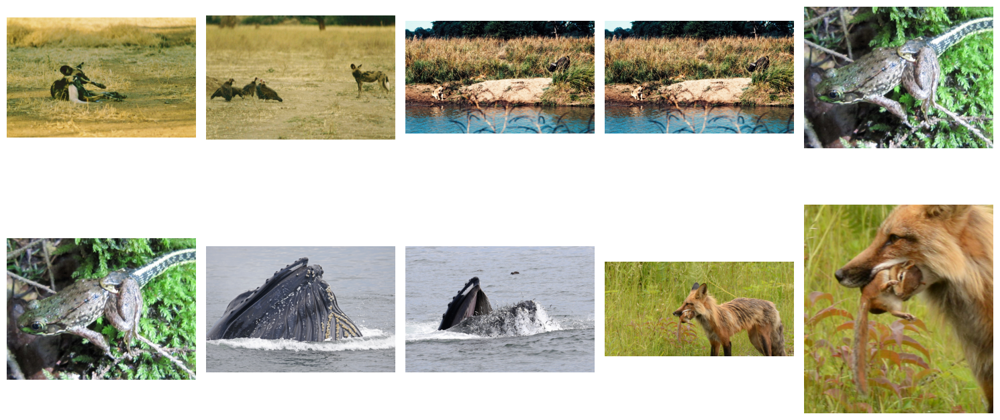

In [112]:
from PIL import Image
import matplotlib.pyplot as plt

n = 20

fig, axes = plt.subplots(2, 5, figsize=(15, 8))

for ax, img_path in zip(axes.flatten(), df_vlm["local_file_path"][:n]):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()